In [34]:
from tensorflow.keras.datasets import cifar10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

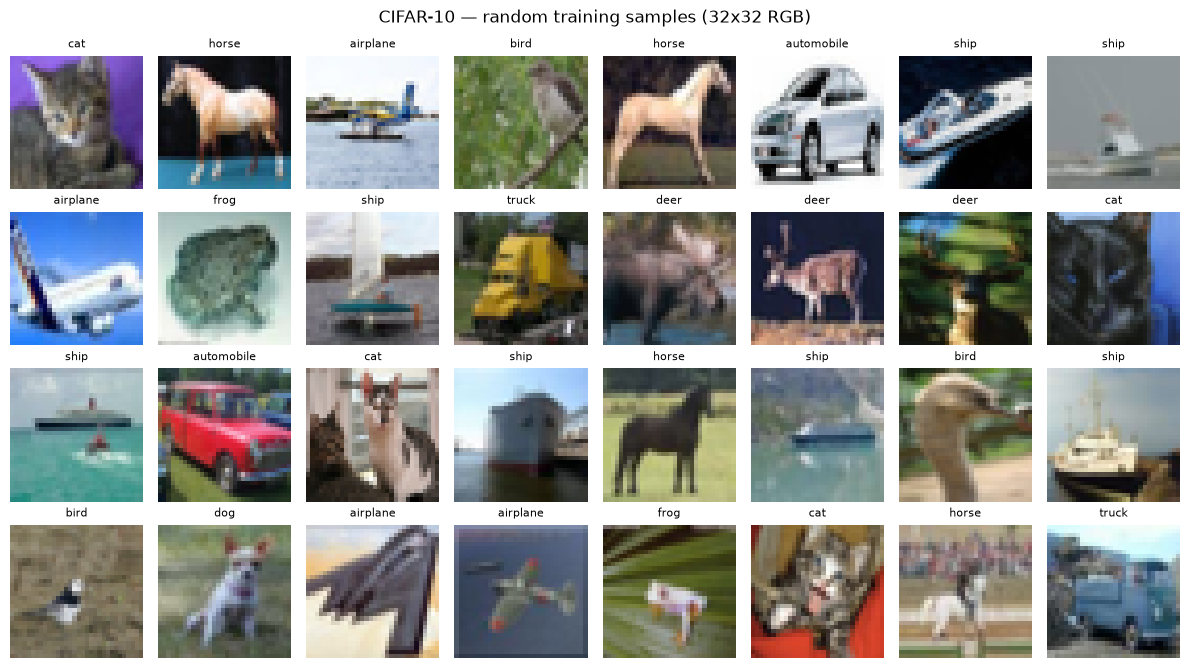

In [35]:
import numpy as np
import matplotlib.pyplot as plt

CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]


def show_samples(X, y, n=32, ncols=8, seed=0):
    """Plot n random samples from (X, y) in a grid with class-name titles."""
    labels = np.asarray(y).ravel()
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=n, replace=False)

    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.5 * ncols, 1.7 * nrows))
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(X[i])  # X is float32 in [0, 1]; imshow handles that
        ax.set_title(CIFAR10_CLASSES[int(labels[i])], fontsize=8)
        ax.axis("off")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle("CIFAR-10 — random training samples (32x32 RGB)", fontsize=12)
    fig.tight_layout()
    plt.show()


show_samples(X_train, y_train, n=32)


In [36]:
def l1_norm(x):
    return np.sum(np.abs(x), axis=-1)


class FuzzyArtMap:
    def __init__(
        self,
        # Baseline ART-a vigilance parameter ``rho`` ∈ [0, 1]. Higher values force finer-grained prototypes.
        vigilance: float,
        lr: float,
        use_complement_coding: bool = True,
        # Match-tracking increment. When a prototype passes vigilance but has a conflicting label, ``vigilance_temp`` is raised to ``match(x, w) + epsilon`` to exclude that prototype from the search.
        epsilon: float = 1e-3,
    ):
        self.vigilance = vigilance
        self.lr = lr
        self.use_complement_coding = use_complement_coding
        self.epsilon = epsilon

        self.prototypes: list[np.ndarray] = []   # ART-a weight vectors
        self.map_field: dict[int, object] = {}   # prototype index -> class label

    def _preprocess(self, x: np.ndarray) -> np.ndarray:
        """Flatten and optionally apply complement coding."""
        x = x.reshape((-1,)).astype(float)
        if self.use_complement_coding:
            x = np.concatenate([x, 1.0 - x])
        return x

    def _activation(self, x: np.ndarray, prototype: np.ndarray) -> float:
        """
        Measures the degree to which ``x`` is a fuzzy subset of ``prototype``
        and is biased toward smaller (more committed) categories via the
        ``1e-1`` denominator offset.
        """
        return l1_norm(np.minimum(x, prototype)) / (1e-1 + l1_norm(prototype))

    def _match(self, x: np.ndarray, prototype: np.ndarray) -> float:
        """
        Returns the degree to which ``x`` is a fuzzy subset of ``prototype``,
        normalised by ``|x|``. Used for **vigilance checking**.
        """
        return l1_norm(np.minimum(x, prototype)) / l1_norm(x)

    def _learn(self, x: np.ndarray, idx: int) -> None:
        """Update prototype ``idx`` toward ``x`` via fuzzy intersection."""
        self.prototypes[idx] = self.lr * np.minimum(x, self.prototypes[idx]) + (1.0 - self.lr) * self.prototypes[idx]

    def _sorted_activations(self, x: np.ndarray) -> list[int]:
        """Return prototype indices sorted by decreasing activation for ``x``."""
        return sorted(
            range(len(self.prototypes)),
            key=lambda j: self._activation(x, self.prototypes[j]),
            reverse=True,
        )

    def fit(self, x: np.ndarray, label: object) -> int:
        """
        Returns
        -------
        int
            Index of the prototype that absorbed the sample.
        """
        x = self._preprocess(x)

        # first ever sample initialises the network.
        if len(self.prototypes) == 0:
            self.prototypes.append(x.copy())
            self.map_field[0] = label
            return 0

        # vigilance_temp starts at the baseline and may only increase within
        # this call (match tracking); it is never written back to self.vigilance.
        vigilance_temp = self.vigilance

        # The search order is determined by activation (highest first). For each candidate prototype:
        for idx in self._sorted_activations(x):
            match_val = self._match(x, self.prototypes[idx])

            if match_val < vigilance_temp:
                # Vigilance not met, try the next-best prototype.
                continue

            # Vigilance test passed and stored label match ground truth
            if self.map_field[idx] == label:
                # Update prototype through learning
                self._learn(x, idx)
                return idx

            # Label conflict: run match tracking: increase the vigilance and continue the search.
            vigilance_temp = match_val + self.epsilon

        # No compatible prototype found, allocate a new one.
        new_idx = len(self.prototypes)
        self.prototypes.append(x.copy())
        self.map_field[new_idx] = label
        return new_idx

    def predict(self, x: np.ndarray) -> object:
        x = self._preprocess(x)

        if not self.prototypes:
            return -1

        for idx in self._sorted_activations(x):
            if self._match(x, self.prototypes[idx]) >= self.vigilance:
                return self.map_field.get(idx, -1)

        return -1

In [37]:
from dataclasses import dataclass, field
import math
from typing import Optional


@dataclass
class Kernel:
    """A single Gaussian kernel within one class GMM."""
    mean: np.ndarray          # shape (d,)
    var: np.ndarray           # diagonal variances, shape (d,)
    phi: float                # receptive field (scalar)
    weight: float             # mixture weight ω
    sample_count: int = 0     # number of training samples attributed to this kernel


class GMM:
    def __init__(self, class_label, d: int, phi_init: float):
        self.label = class_label
        self.d = d
        self.phi_init = phi_init
        self.kernels: list[Kernel] = []
        self.count: int = 0          # number of training samples seen so far

    def _activation(self, x: np.ndarray, k: Kernel) -> float:
        """Compute f(x; μ, Σ, φ) for one kernel (Eq. 3)."""
        safe_var = np.where(k.var > 1e-300, k.var, 1e-300)
        diff = x - k.mean
        mahal = np.sum(diff ** 2 / safe_var)
        phi2 = max(k.phi ** 2, 1e-300)
        norm = 1.0 / math.sqrt(2.0 * math.pi * phi2)
        return norm * math.exp(-mahal / (2.0 * phi2))

    def density(self, x: np.ndarray) -> float:
        """p(x) = Σ ω_i · f(x; μ_i, Σ_i, φ_i)"""
        if not self.kernels:
            return 0.0
        return sum(k.weight * self._activation(x, k) for k in self.kernels)

    def max_activation(self, x: np.ndarray) -> float:
        """Classification uses max kernel activation per class (Eq. 21)."""
        if not self.kernels:
            return 0.0
        return max(k.weight * self._activation(x, k) for k in self.kernels)

    def _posterior(self, x: np.ndarray, k: Kernel) -> float:
        p = self.density(x)
        if p < 1e-300:
            return 0.0
        return k.weight * self._activation(x, k) / p

    def update_parameters(self, x: np.ndarray, n: int):
        """Update μ, σ², ω for all kernels given new sample x (Eqs. 4-6)."""
        for k in self.kernels:
            p_ix = self._posterior(x, k)
            n_safe = max(n, 1)
            k.mean = k.mean + p_ix * (x - k.mean) / (n_safe * k.weight + 1e-300)
            k.var = k.var + p_ix * ((x - k.mean) ** 2 - k.var) / (n_safe * k.weight + 1e-300)
            k.var = np.maximum(k.var, 1e-10)
            k.weight = k.weight + (p_ix - k.weight) / n_safe

        total = sum(k.weight for k in self.kernels)
        if total > 1e-300:
            for k in self.kernels:
                k.weight /= total

    def update_receptive_field(self, x: np.ndarray, n: int, alpha: float):
        """Adjust φ of the closest kernel on misclassification (Eq. 7)."""
        if not self.kernels:
            return
        acts = [self._activation(x, k) for k in self.kernels]
        r = int(np.argmax(acts))
        k = self.kernels[r]

        safe_var = np.where(k.var > 1e-300, k.var, 1e-300)
        diff = x - k.mean
        mahal = float(np.sum(diff ** 2 / safe_var))

        p_rx = self._posterior(x, k)
        n_safe = max(n, 1)
        w_safe = max(k.weight, 1e-300)

        update = p_rx * (mahal / max(self.d, 1) - k.phi ** 2) / (n_safe * w_safe ** 2)
        if alpha > 0.0:
            update = np.clip(update, -alpha, alpha)
        k.phi = math.sqrt(max(k.phi ** 2 + update, 1e-10))

    def _weighted_mean_var_phi(self):
        total_w = sum(k.weight for k in self.kernels)
        if total_w < 1e-300:
            return np.ones(self.d), 1.0
        mean_var = sum(k.weight * k.var for k in self.kernels) / total_w
        mean_phi2 = sum(k.weight * k.phi ** 2 for k in self.kernels) / total_w
        return mean_var, math.sqrt(max(mean_phi2, 1e-10))

    def add_kernel(self, x: np.ndarray, n: int, K_total: int):
        """Add a new kernel centred at x (Eqs. 8-10)."""
        if not self.kernels:
            new_k = Kernel(
                mean=x.copy(),
                var=np.ones(self.d),
                phi=math.sqrt(self.phi_init),
                weight=1.0,
            )
        else:
            mean_var, mean_phi = self._weighted_mean_var_phi()
            n_safe = max(n, 1)
            new_weight = 1.0 / n_safe
            scale = (n_safe - 1) / n_safe
            for k in self.kernels:
                k.weight *= scale
            new_k = Kernel(
                mean=x.copy(),
                var=mean_var.copy(),
                phi=mean_phi,
                weight=new_weight,
            )
        self.kernels.append(new_k)
        self._renorm_weights()

    def _renorm_weights(self):
        total = sum(k.weight for k in self.kernels)
        if total > 1e-300:
            for k in self.kernels:
                k.weight /= total

    @staticmethod
    def _ellipsoid_volume(var: np.ndarray, d: int) -> float:
        radii = np.sqrt(np.maximum(var, 1e-300))
        prod_r = float(np.prod(radii))
        gamma_d2 = math.gamma(d / 2.0)
        if gamma_d2 < 1e-300 or d == 0:
            return 1e-300
        volume = 2.0 * prod_r * (math.pi ** (d / 2.0)) / (d * gamma_d2)
        return max(volume, 1e-300)

    def _proximity_test(self, p: Kernel, q: Kernel, fac: float, t: float) -> bool:
        diff = np.abs(p.mean - q.mean)
        total_diff = float(np.sum(diff))
        if total_diff < 1e-300:
            return True
        spread = fac * (np.sqrt(p.var) + np.sqrt(q.var))
        weighted_spread = float(np.sum(diff * spread)) / total_diff
        dist = float(np.linalg.norm(p.mean - q.mean))
        threshold = weighted_spread + math.sqrt(self.d) * t
        return dist <= threshold

    def _homogeneity_test(self, p: Kernel, q: Kernel, d: int) -> bool:
        total_w = p.weight + q.weight
        if total_w < 1e-300:
            return False
        mean_t = (p.weight * p.mean + q.weight * q.mean) / total_w
        var_t = (
            p.weight * p.var / total_w + (p.mean - mean_t) ** 2
            + (q.mean - mean_t) ** 2
            + q.weight * q.var / total_w
        )
        Vp = self._ellipsoid_volume(p.var, d)
        Vq = self._ellipsoid_volume(q.var, d)
        Vt = self._ellipsoid_volume(var_t, d)
        return Vt <= d * (Vp + Vq)

    def _merge_kernels(self, p: Kernel, q: Kernel) -> Kernel:
        """Produce merged kernel from p and q (Eqs. 15-18). Sums sample counts."""
        total_w = p.weight + q.weight
        mean_t = (p.weight * p.mean + q.weight * q.mean) / total_w
        var_t = (
            p.weight * p.var / total_w
            + (p.mean - mean_t) ** 2
            + (q.mean - mean_t) ** 2
            + q.weight * q.var / total_w
        )
        phi2_t = (p.weight * p.phi ** 2 + q.weight * q.phi ** 2) / total_w
        return Kernel(
            mean=mean_t,
            var=np.maximum(var_t, 1e-10),
            phi=math.sqrt(max(phi2_t, 1e-10)),
            weight=total_w,
            sample_count=p.sample_count + q.sample_count,
        )

    def try_merge(self, x: np.ndarray, fac: float, t: float):
        if len(self.kernels) < 2:
            return
        acts = [self._activation(x, k) for k in self.kernels]
        top2 = np.argsort(acts)[-2:]
        pi, qi = int(top2[1]), int(top2[0])
        p, q = self.kernels[pi], self.kernels[qi]

        if self._proximity_test(p, q, fac, t) and self._homogeneity_test(p, q, self.d):
            merged = self._merge_kernels(p, q)
            keep = [i for i in range(len(self.kernels)) if i not in (pi, qi)]
            self.kernels = [self.kernels[i] for i in keep]
            self.kernels.append(merged)
            self._renorm_weights()

    def prune_kernels(self, n: int, s: float):
        threshold = 1.0 / (n + s)
        self.kernels = [k for k in self.kernels if k.weight >= threshold]
        if self.kernels:
            self._renorm_weights()


class ePNN:
    def __init__(
        self,
        n_max: int = 100,
        phi_init: float = 0.25,
        t: float = 0.0,
        alpha: float = 0.001,
        fac: float = 2.0,
        s: float = 1.0,
        update_variance: bool = True,
    ):
        self.n_max = n_max
        self.phi_init = phi_init
        self.t = t
        self.alpha = alpha
        self.fac = fac
        self.s = s
        self.update_variance = update_variance

        self.gmms: dict[any, GMM] = {}
        self.d: Optional[int] = None

    @property
    def total_kernels(self) -> int:
        return sum(len(g.kernels) for g in self.gmms.values())

    def train(self, X: np.ndarray, y):
        X = np.asarray(X, dtype=float)

        if self.d is None:
            self.d = X.shape[0]

        if y not in self.gmms:
            gmm = GMM(y, self.d, self.phi_init)
            self.gmms[y] = gmm
            gmm.add_kernel(X, n=1, K_total=self.total_kernels)
            gmm.kernels[-1].sample_count = 1
            gmm.count = 1
            return

        gmm = self.gmms[y]
        gmm.count += 1
        n = min(gmm.count, self.n_max)

        y_pred = self.predict(X)
        gmm.update_parameters(X, n)

        if y_pred != y:
            gmm.update_receptive_field(X, n, self.alpha)
            gmm.add_kernel(X, n=n, K_total=self.total_kernels)
            gmm.kernels[-1].sample_count = 1
        else:
            posteriors = [gmm._posterior(X, k) for k in gmm.kernels]
            if posteriors:
                gmm.kernels[int(np.argmax(posteriors))].sample_count += 1

        gmm.try_merge(X, fac=self.fac, t=self.t)
        gmm.prune_kernels(n, self.s)

    def predict(self, X: np.ndarray):
        if not self.gmms:
            return None
        best_label, best_act = None, -1.0
        for label, gmm in self.gmms.items():
            act = gmm.max_activation(X)
            if act > best_act:
                best_act = act
                best_label = label
        return best_label

### Building the incremental dataset splits

In [38]:
from sklearn.model_selection import train_test_split

# Flatten each 32x32x3 image to a 3072-d vector and merge the predefined
# train/test partitions so we can re-split with the exact same protocol used
# for MNIST (stratified 80/20, seed 42).
cifar_X = np.concatenate([X_train, X_test]).reshape(len(X_train) + len(X_test), -1).astype("float32")
cifar_y = np.concatenate([y_train, y_test]).ravel().astype("int64")

# Classes 0-4: phases 1 (first half) and 2 (second half)
mask_0_to_4 = (cifar_y >= 0) & (cifar_y <= 4)
X_04, y_04 = cifar_X[mask_0_to_4], cifar_y[mask_0_to_4]
X_train_04, X_test_04, y_train_04, y_test_04 = train_test_split(
    X_04, y_04, test_size=0.2, random_state=42, stratify=y_04
)
mid = len(X_train_04) // 2
X_train_half1, y_train_half1 = X_train_04[:mid], y_train_04[:mid]
X_train_half2, y_train_half2 = X_train_04[mid:], y_train_04[mid:]

# Classes 5-9: phase 3 (new classes)
mask_5_to_9 = (cifar_y >= 5) & (cifar_y <= 9)
X_59, y_59 = cifar_X[mask_5_to_9], cifar_y[mask_5_to_9]
X_train_59, X_test_59, y_train_59, y_test_59 = train_test_split(
    X_59, y_59, test_size=0.2, random_state=42, stratify=y_59
)

# Whole dataset
X_cp = cifar_X
y_cp = cifar_y
X_train, X_test, y_train, y_test = train_test_split(
    X_cp, y_cp, test_size=0.2, random_state=42, stratify=y_cp
)

print(f"Classes 0-4 - train: {len(X_train_04)}, test: {len(X_test_04)}")
print(f"  Half 1: {len(X_train_half1)} | Half 2: {len(X_train_half2)}")
print(f"Classes 5-9 - train: {len(X_train_59)}, test: {len(X_test_59)}")

Classes 0-4 - train: 24000, test: 6000
  Half 1: 12000 | Half 2: 12000
Classes 5-9 - train: 24000, test: 6000


In [39]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

n_components = 150
pca = PCA(n_components=n_components, random_state=42)
scaler = StandardScaler()

# Fit only on the first half; transform everything else with the same transform
X_epnn_half1 = scaler.fit_transform(pca.fit_transform(X_train_half1))
X_epnn_half2 = scaler.transform(pca.transform(X_train_half2))
X_epnn_train_59 = scaler.transform(pca.transform(X_train_59))
X_epnn_test_04 = scaler.transform(pca.transform(X_test_04))
X_epnn_test_59 = scaler.transform(pca.transform(X_test_59))

print(f"PCA explained variance: {pca.explained_variance_ratio_.sum() * 100:.1f}%")

PCA explained variance: 93.4%


In [40]:
from sklearn.preprocessing import MinMaxScaler

# FuzzyArtMap requires inputs in [0, 1]. Reuse the same fitted PCA used for
# ePNN above, but rescale with MinMaxScaler (fit on the same first-half
# split) instead of StandardScaler, then clip in case later phases produce
# values slightly outside the fitted range.
minmax_scaler = MinMaxScaler()

X_famap_half1 = np.clip(minmax_scaler.fit_transform(pca.transform(X_train_half1)), 0.0, 1.0)
X_famap_half2 = np.clip(minmax_scaler.transform(pca.transform(X_train_half2)), 0.0, 1.0)
X_famap_train_59 = np.clip(minmax_scaler.transform(pca.transform(X_train_59)), 0.0, 1.0)
X_famap_test_04 = np.clip(minmax_scaler.transform(pca.transform(X_test_04)), 0.0, 1.0)
X_famap_test_59 = np.clip(minmax_scaler.transform(pca.transform(X_test_59)), 0.0, 1.0)

print(f"FuzzyArtMap features range: [{X_famap_half1.min():.3f}, {X_famap_half1.max():.3f}]")

FuzzyArtMap features range: [0.000, 1.000]


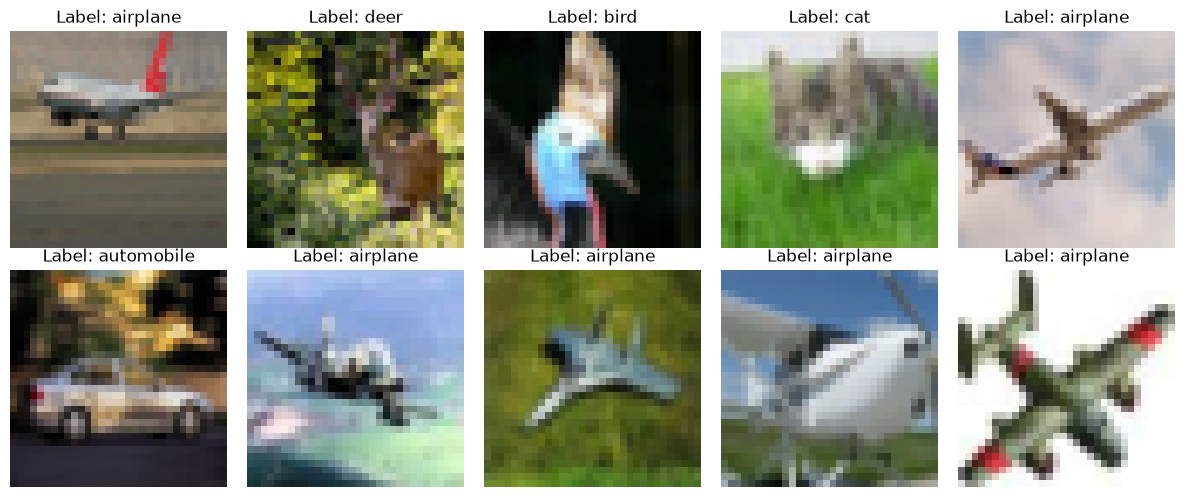

In [41]:
n = 10
idx = np.random.choice(len(X_04), n, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_04[i].reshape(32, 32, 3))
    ax.set_title(f"Label: {CIFAR10_CLASSES[int(y_04[i])]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Auxiliar functions

In [42]:
import re
from collections import Counter
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd


def predict_famap(net, X):
    preds = []
    for x in X:
        p = net.predict(x)
        preds.append(p if p != -1 else -999)
    return np.array(preds)


def predict_epnn(net, X):
    preds = []
    for x in X:
        p = net.predict(x)
        preds.append(p if p is not None else -999)
    return np.array(preds)


def predict_kmeans(models, X):
    preds = []
    for x in X:
        min_dist = np.inf
        prd_lbl = -1
        for lbl, model in models.items():
            dists = np.linalg.norm(x - model.cluster_centers_, axis=1)
            d = dists.min()
            if d < min_dist:
                min_dist = d
                prd_lbl = lbl
        preds.append(prd_lbl)
    return np.array(preds)


def compute_metrics(y_true, y_pred, model_name, labels=None, average="macro"):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, labels=labels, average=average, zero_division=0),
        "Recall": recall_score(y_true, y_pred, labels=labels, average=average, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, labels=labels, average=average, zero_division=0),
    }


def compute_metrics_per_class(y_true, y_pred, model_name, labels):
    report = classification_report(y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
    rows = []
    for digit in labels:
        key = str(digit)
        if key in report:
            rows.append({
                "Model": model_name, "Class": digit,
                "Precision": report[key]["precision"],
                "Recall": report[key]["recall"],
                "F1-score": report[key]["f1-score"],
                "Support": int(report[key]["support"]),
            })
    return rows


def print_comparison(model_preds, y_true, class_labels, title="Comparison"):
    """model_preds: dict of {model_name: predictions_array}"""
    print(f"\n{'='*55}")
    print(f"  {title}")
    print(f"{'='*55}")

    rows = [compute_metrics(y_true, preds, name, labels=class_labels) for name, preds in model_preds.items()]
    df = pd.DataFrame(rows)
    for col in ["Accuracy", "Precision", "Recall", "F1-score"]:
        df[col] = (df[col] * 100).round(2).astype(str) + "%"
    print("\nAggregate (macro-average):")
    print(df.to_string(index=False))

    per_class_rows = []
    for name, preds in model_preds.items():
        per_class_rows.extend(compute_metrics_per_class(y_true, preds, name, class_labels))
    df2 = pd.DataFrame(per_class_rows)
    for col in ["Precision", "Recall", "F1-score"]:
        df2[col] = (df2[col] * 100).round(2).astype(str) + "%"
    print("\nPer-class metrics:")
    print(df2.to_string(index=False))


PLOT_TITLE_FONTSIZE = 30
PLOT_LABEL_FONTSIZE = 28
PLOT_TICK_FONTSIZE = 27
PLOT_ANNOT_FONTSIZE = 26


def plot_fuzzyart_cluster_sizes(assignments, title="FuzzyArtMap Cluster Size Distribution", output_path=None):
    """Bar chart: x = samples per cluster, y = number of clusters (log scale)."""
    valid = assignments[assignments >= 0]
    _, counts = np.unique(valid, return_counts=True)

    size_counts = np.bincount(counts)          # index = cluster size, value = how many clusters have that size
    sizes = np.arange(len(size_counts))

    mask = (sizes > 0) & (size_counts > 0)
    sizes, size_counts = sizes[mask], size_counts[mask]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(sizes, size_counts, color="#4C78A8", width=1)
    ax.set_yscale("log")
    ax.set_xlabel("Samples per Cluster", fontsize=PLOT_LABEL_FONTSIZE)
    ax.set_ylabel("Number of Clusters (log scale)", fontsize=PLOT_LABEL_FONTSIZE)
    ax.set_title(
        f"{title}\n"
        f"total clusters: {len(counts)} | mean size: {np.mean(counts):.2f} | median: {int(np.median(counts))}",
        fontsize=PLOT_TITLE_FONTSIZE,
    )
    ax.tick_params(axis="both", labelsize=PLOT_TICK_FONTSIZE)
    ax.grid(True, axis="y", which="both", alpha=0.3)
    ax.set_xlim(0, 200)
    plt.tight_layout()
    plt.show()

### Training: 1st half of classes 0 - 4

- Fuzzy Art Map

In [43]:
# -- Phase 1: FuzzyArtMap -- first half of classes 0-4 --------------------
net_famap = FuzzyArtMap(
    vigilance=0.8,
    lr=0.5,
    use_complement_coding=True,
    epsilon=1e-3,
)

assignments_half1 = np.full(len(X_famap_half1), -1, dtype=np.int32)
for i in range(len(X_famap_half1)):
    assignments_half1[i] = net_famap.fit(X_famap_half1[i], int(y_train_half1[i]))

print(f"Active clusters: {len(net_famap.prototypes)}")
print(f"Trained samples: {np.sum(assignments_half1 >= 0)}")

Active clusters: 2411
Trained samples: 12000


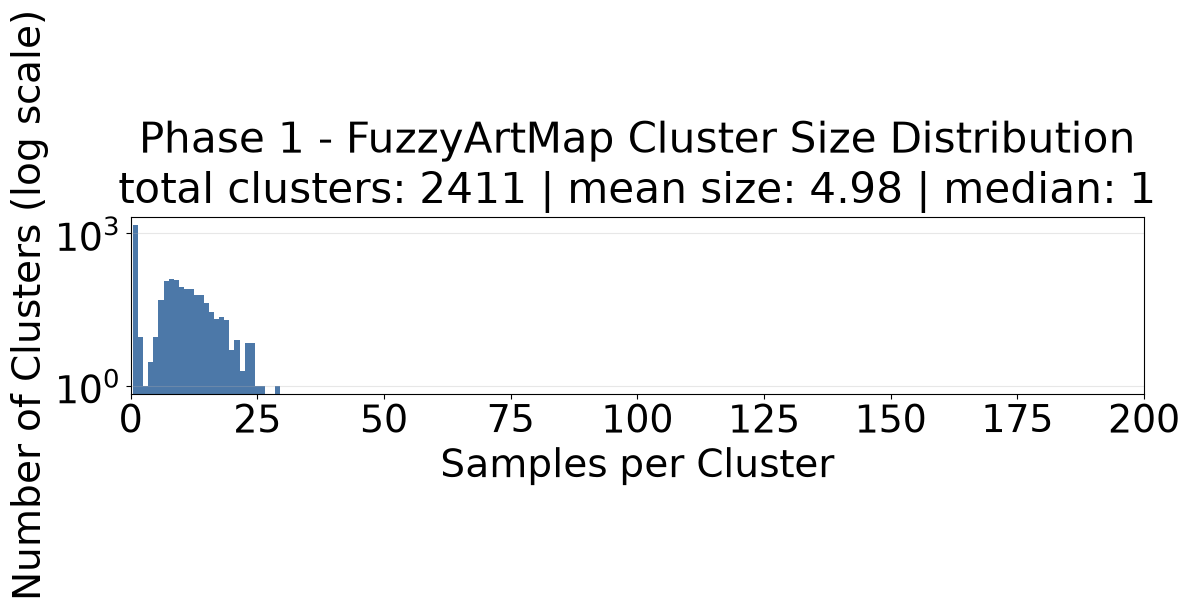

In [44]:
plot_fuzzyart_cluster_sizes(assignments_half1, "Phase 1 - FuzzyArtMap Cluster Size Distribution")

Total clusters found: 2411


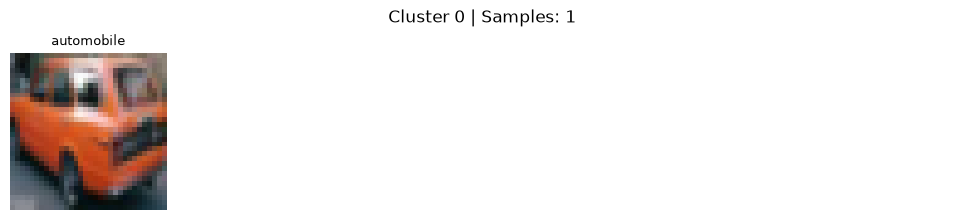

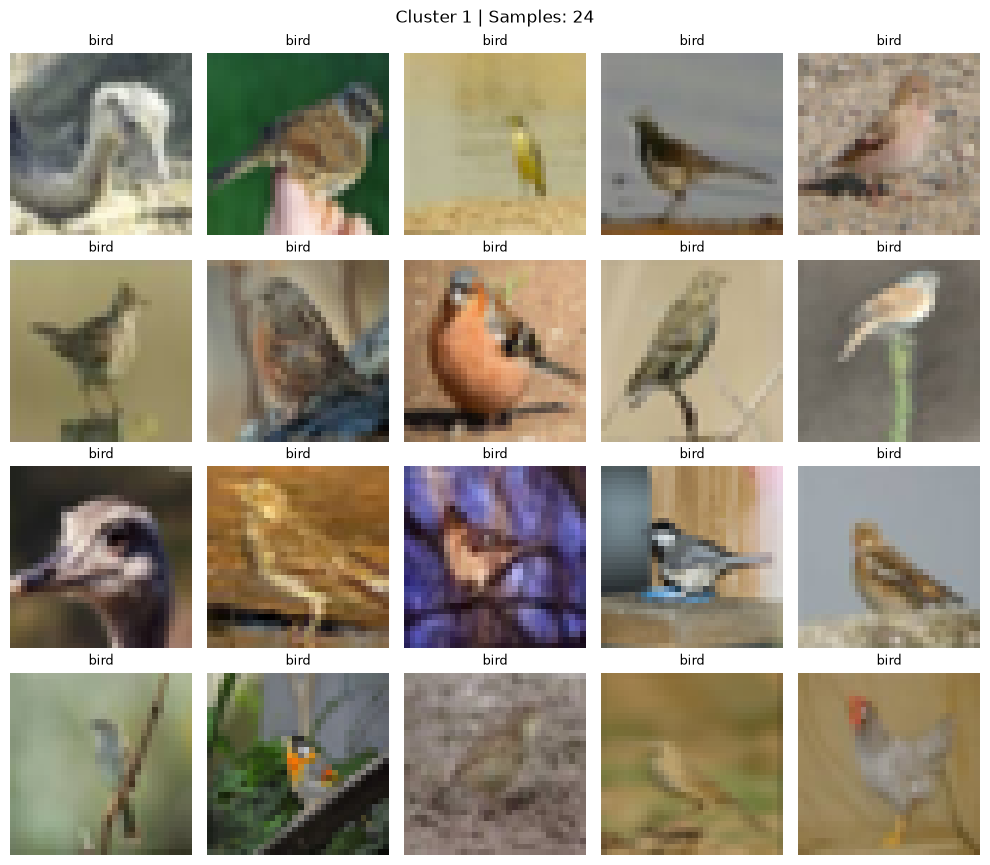

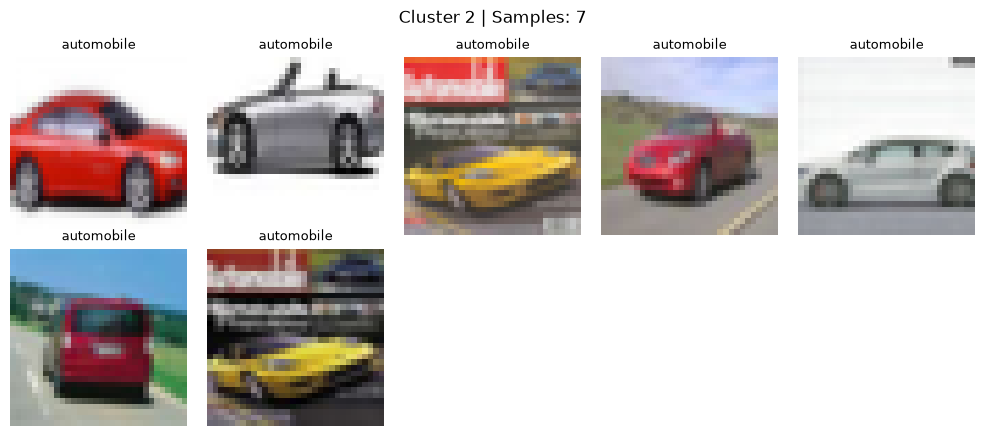

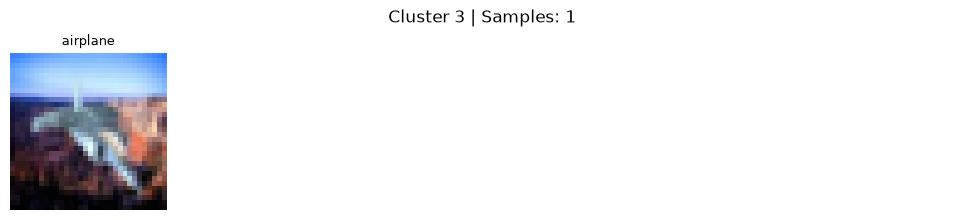

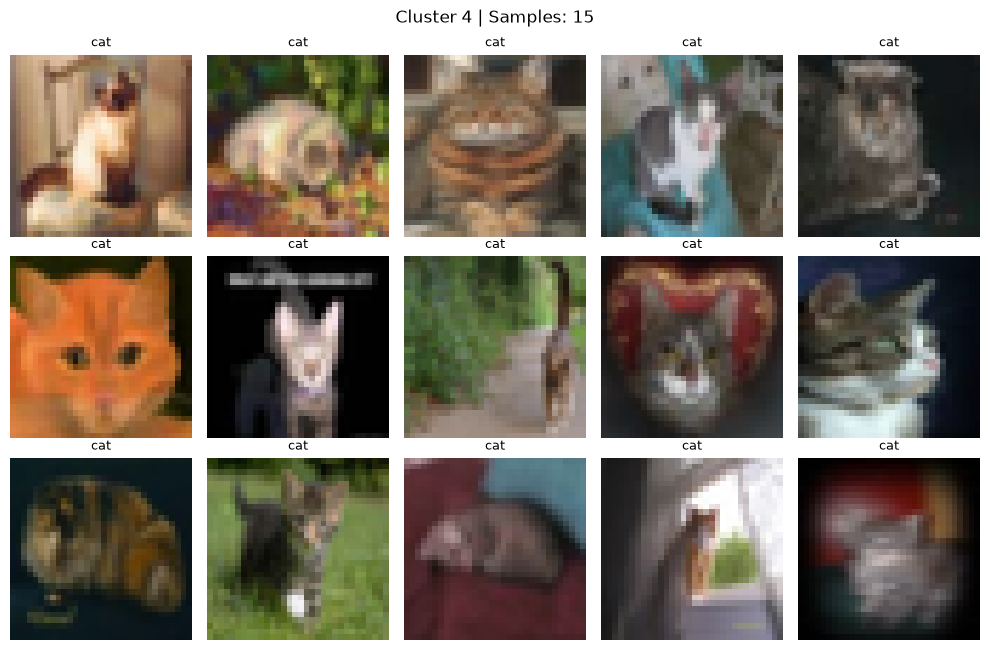

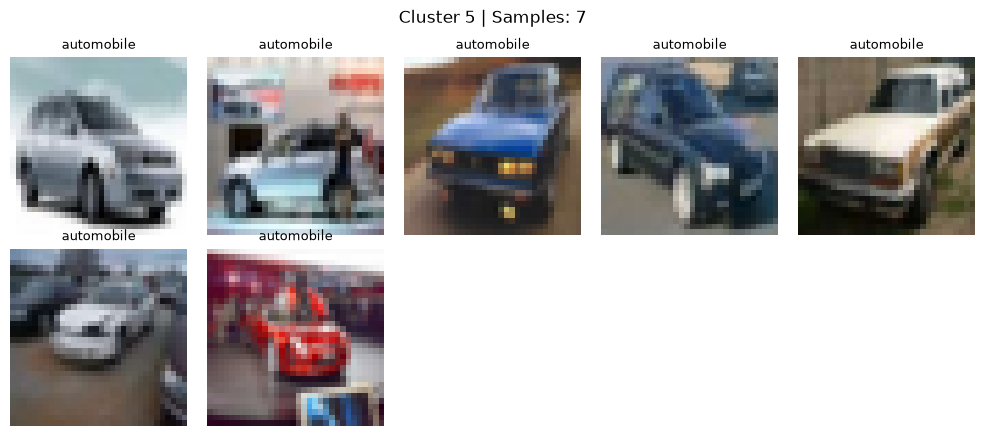

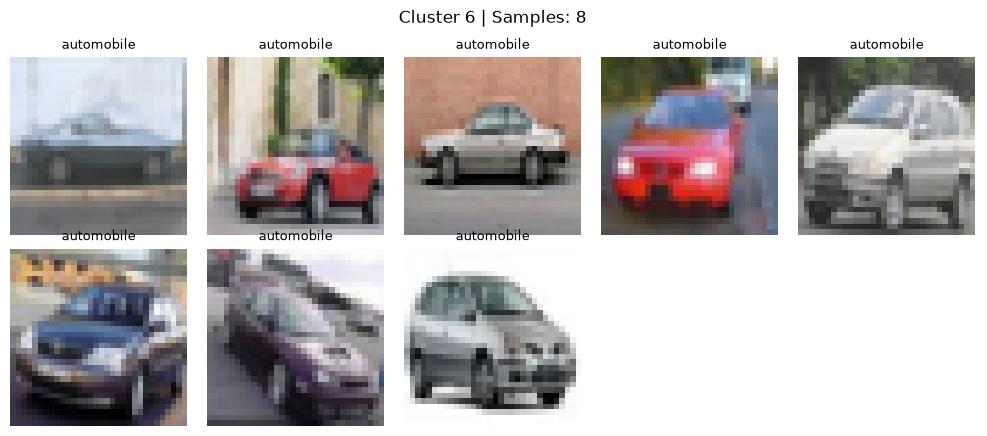

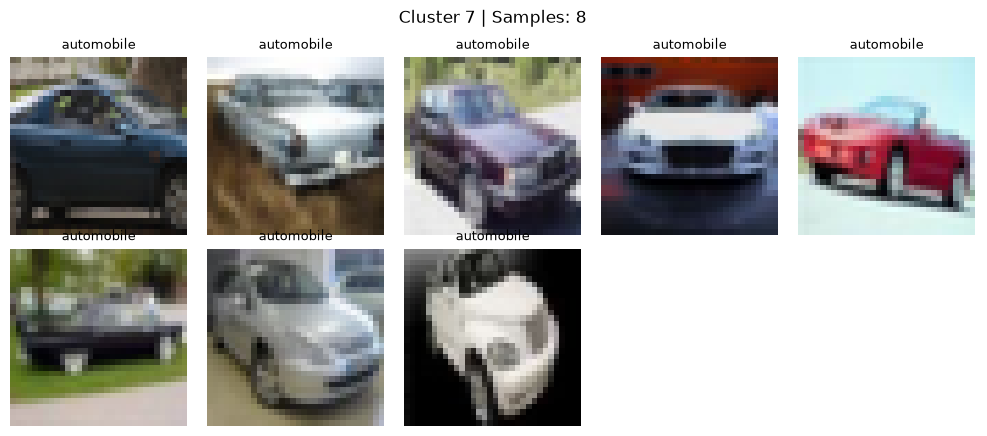

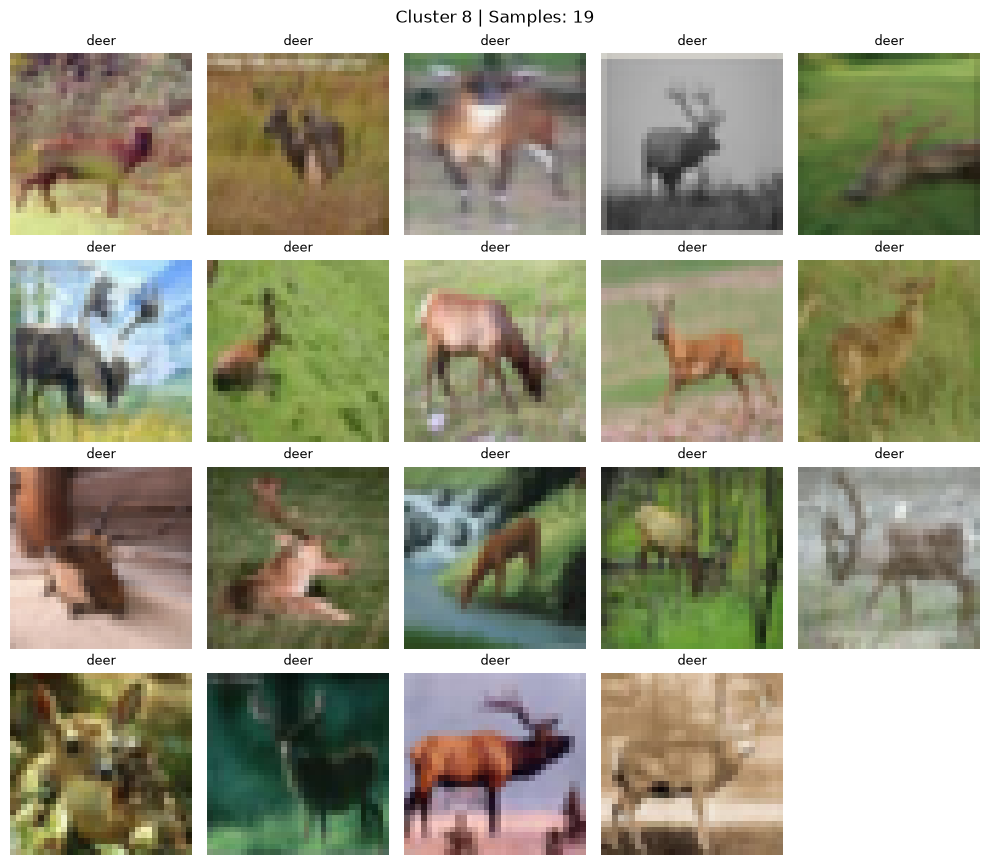

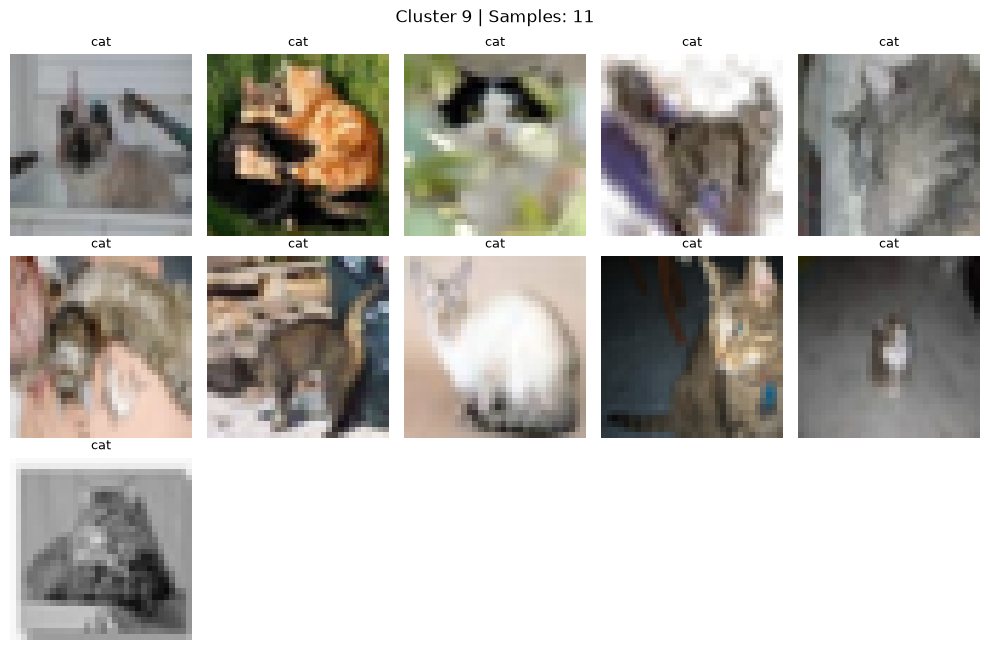

In [45]:
samples_per_cluster = 20
cluster_ids = np.unique(assignments_half1)

print(f"Total clusters found: {len(cluster_ids)}")

for cluster_id in cluster_ids[:10]:
    idx = np.where(assignments_half1 == cluster_id)[0]
    if len(idx) == 0:
        continue

    n_show = min(samples_per_cluster, len(idx))
    show_idx = np.random.choice(idx, size=n_show, replace=False)

    cols = 5
    rows = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    axes = np.array(axes).reshape(-1)

    for ax, sample_i in zip(axes, show_idx):
        ax.imshow(X_train_half1[sample_i].reshape(32, 32, 3))
        ax.set_title(f"{CIFAR10_CLASSES[int(y_train_half1[sample_i])]}", fontsize=9)
        ax.axis("off")

    for ax in axes[n_show:]:
        ax.axis("off")

    fig.suptitle(f"Cluster {cluster_id} | Samples: {len(idx)}", fontsize=12)
    plt.tight_layout()
    plt.show()

- ePNN

In [46]:
# -- Phase 1: ePNN -- first half of classes 0-4 --------------------------
net_epnn = ePNN(
    n_max=500,
    phi_init=0.50,
    t=0.0,
    alpha=0.05,
    fac=1.2,
    s=0.5,
)

for i in range(len(X_epnn_half1)):
    net_epnn.train(X_epnn_half1[i], int(y_train_half1[i]))

train_correct = sum(
    net_epnn.predict(X_epnn_half1[i]) == int(y_train_half1[i])
    for i in range(len(X_epnn_half1))
)
print(f"ePNN train accuracy (Phase 1): {train_correct / len(X_epnn_half1) * 100:.2f}% ({train_correct}/{len(X_epnn_half1)})")

ePNN train accuracy (Phase 1): 20.98% (2518/12000)


- MiniBatchKMeans

In [47]:
# -- Phase 1: MiniBatchKMeans -- first half of classes 0-4 ---------------
import time
from sklearn.cluster import MiniBatchKMeans

N_CLUSTERS_PER_CLASS = 15
kmeans_models = {}

t0 = time.time()
for digit in range(5):
    mask = y_train_half1 == digit
    X_digit = X_epnn_half1[mask]
    kmeans_models[digit] = MiniBatchKMeans(n_clusters=N_CLUSTERS_PER_CLASS, n_init=5, random_state=42)
    kmeans_models[digit].fit(X_digit)

dt = time.time() - t0
print(f"MiniBatchKMeans Phase 1 done in {dt:.2f}s")
print(f"Models trained for classes: {sorted(kmeans_models.keys())}")

MiniBatchKMeans Phase 1 done in 0.29s
Models trained for classes: [0, 1, 2, 3, 4]


- MLP

In [48]:
# -- Phase 1: MLP -- first half of classes 0-4 ---------------------------
from sklearn.neural_network import MLPClassifier

MLP_EPOCHS_PER_PHASE = 20
ALL_CLASSES = np.arange(10)

net_mlp = MLPClassifier(
    hidden_layer_sizes=(128),
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    random_state=42,
)


def train_mlp_phase(net, X, y, epochs=MLP_EPOCHS_PER_PHASE, seed=42):
    # Only the current phase's data is replayed, so the MLP faces the same
    # incremental constraint as the other networks.
    rng = np.random.default_rng(seed)
    y = np.asarray(y, dtype=int)
    for _ in range(epochs):
        order = rng.permutation(len(X))
        net.partial_fit(X[order], y[order], classes=ALL_CLASSES)
    return net


t0 = time.time()
train_mlp_phase(net_mlp, X_epnn_half1, y_train_half1, seed=42)
dt = time.time() - t0

train_acc = np.mean(net_mlp.predict(X_epnn_half1) == y_train_half1)
print(f"MLP Phase 1 done in {dt:.2f}s")
print(f"MLP train accuracy (Phase 1): {train_acc * 100:.2f}%")

MLP Phase 1 done in 1.53s
MLP train accuracy (Phase 1): 89.49%


### Testing and comparing the models

In [49]:
# -- Phase 1: Evaluation --------------------------------------------------
fuzzy_preds_1 = predict_famap(net_famap, X_famap_test_04)
epnn_preds_1 = predict_epnn(net_epnn, X_epnn_test_04)
kmeans_preds_1 = predict_kmeans(kmeans_models, X_epnn_test_04)
mlp_preds_1 = net_mlp.predict(X_epnn_test_04)

print_comparison(
    {"ePNN": epnn_preds_1, "FuzzyArtMap": fuzzy_preds_1, "MiniBatchKMeans": kmeans_preds_1, "MLP": mlp_preds_1},
    y_test_04, list(range(5)),
    "Phase 1 - First Half (Classes 0-4)"
)


  Phase 1 - First Half (Classes 0-4)

Aggregate (macro-average):
          Model Accuracy Precision Recall F1-score
           ePNN   20.52%    28.23% 20.52%    7.73%
    FuzzyArtMap   29.87%    33.47% 29.87%   30.14%
MiniBatchKMeans   50.45%    54.34% 50.45%   49.87%
            MLP    61.6%    61.49%  61.6%   61.49%

Per-class metrics:
          Model  Class Precision Recall F1-score  Support
           ePNN      0    80.95%  1.42%    2.78%     1200
           ePNN      1    20.19% 100.0%    33.6%     1200
           ePNN      2      0.0%   0.0%     0.0%     1200
           ePNN      3     40.0%  1.17%    2.27%     1200
           ePNN      4      0.0%   0.0%     0.0%     1200
    FuzzyArtMap      0    38.31% 28.25%   32.52%     1200
    FuzzyArtMap      1    32.13% 32.58%   32.35%     1200
    FuzzyArtMap      2    21.85% 39.25%   28.07%     1200
    FuzzyArtMap      3    26.91% 26.17%   26.53%     1200
    FuzzyArtMap      4    48.17% 23.08%   31.21%     1200
MiniBatchKMeans      

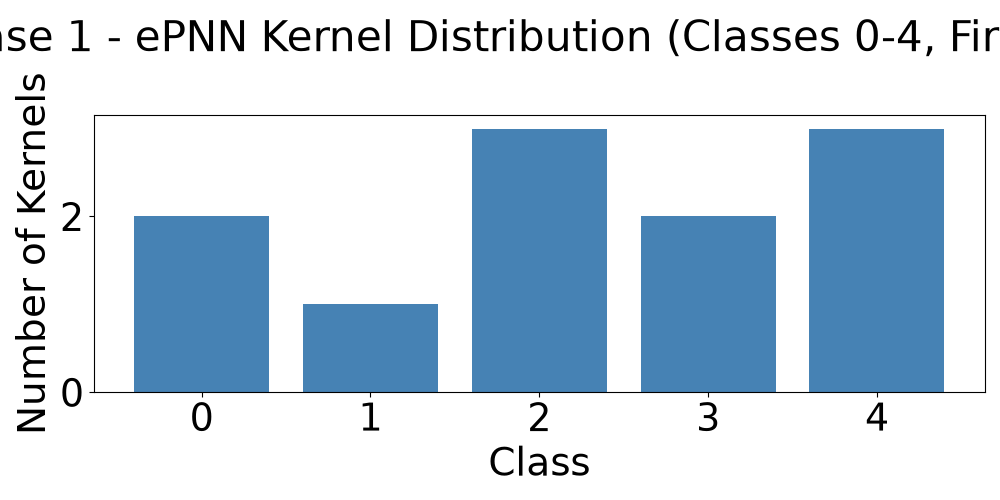

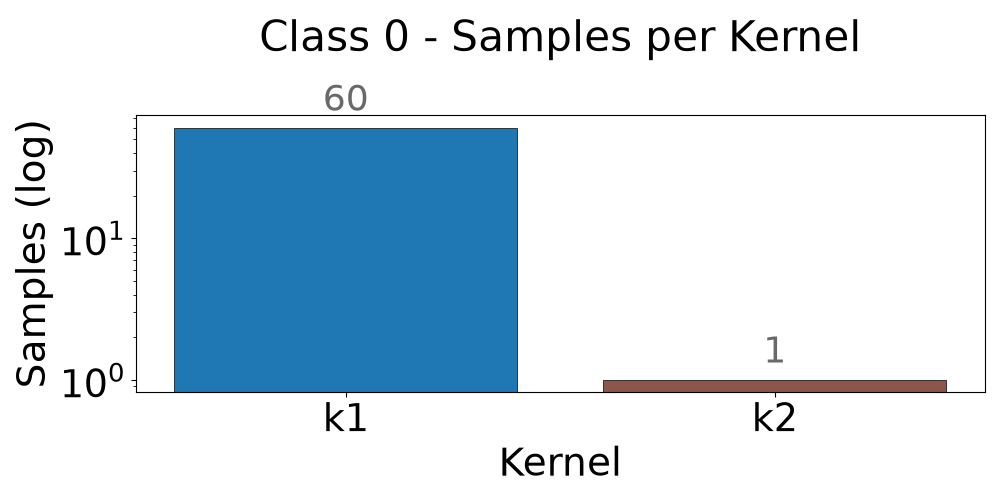

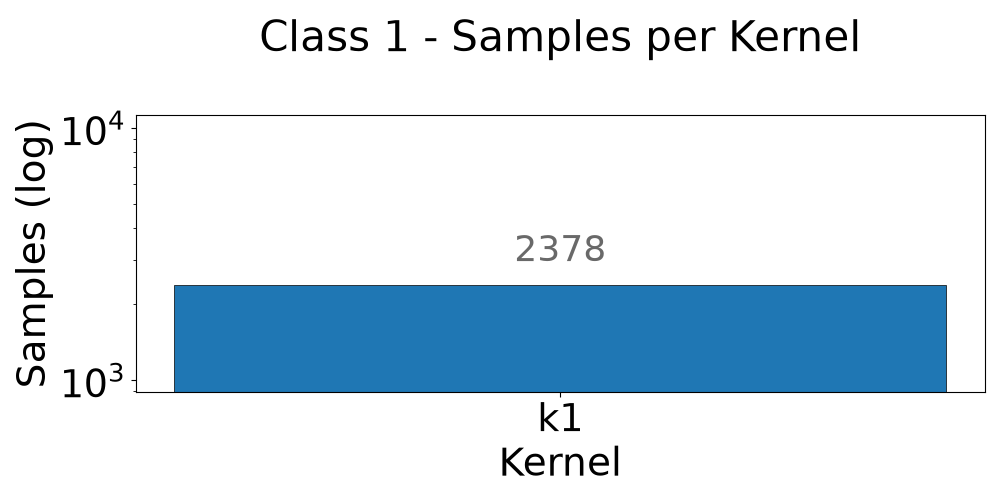

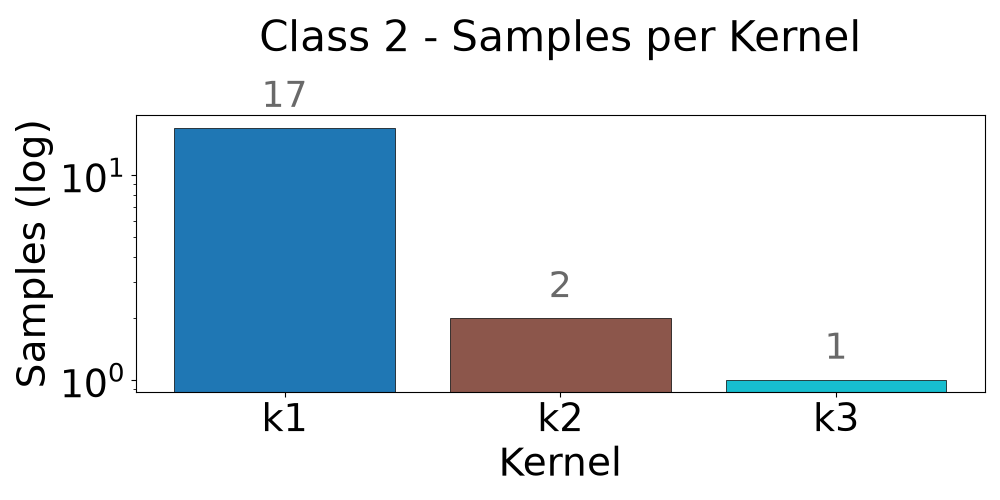

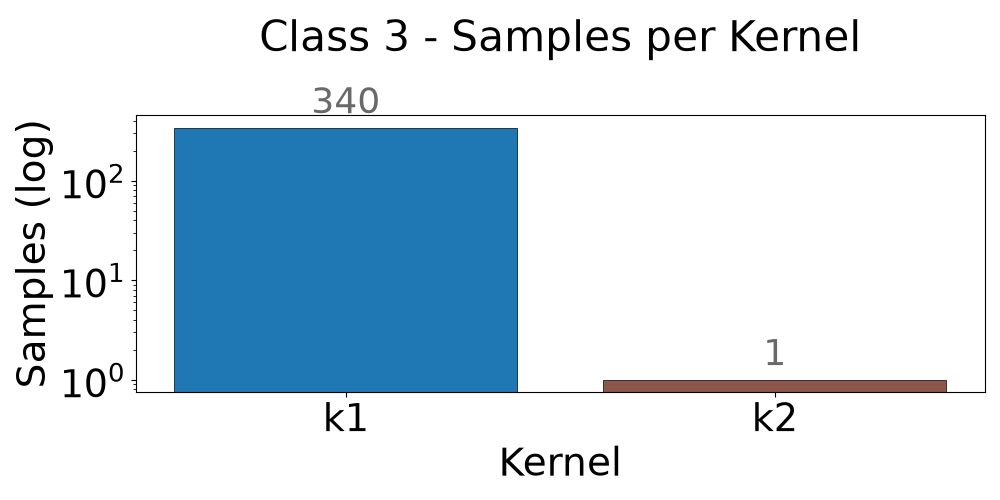

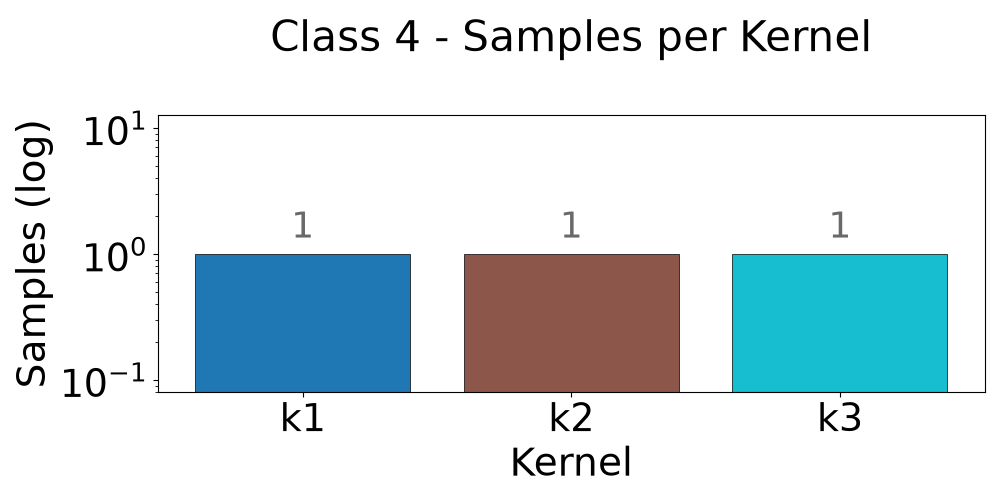

In [50]:
import io

import matplotlib.cm as cm
from IPython.display import Image, display


def _show_fixed_size(fig):
    # Jupyter's inline backend crops figures with bbox_inches="tight" by
    # default, so figures with the same figsize can still render at
    # different pixel sizes depending on their content (labels, titles...).
    # Saving explicitly with bbox_inches=None keeps every figure the exact
    # size given by figsize/dpi.
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=fig.dpi, bbox_inches=None)
    plt.close(fig)
    buf.seek(0)
    display(Image(data=buf.getvalue()))


def plot_epnn_kernels(net, title="ePNN Kernel Distribution"):
    classes = sorted(net.gmms.keys())
    if not classes:
        print("No classes in ePNN.")
        return

    kernels_per_class = [len(net.gmms[c].kernels) for c in classes]
    samples_by_class = [[k.sample_count for k in net.gmms[c].kernels] for c in classes]

    max_kernels = max((len(s) for s in samples_by_class), default=1)
    cmap = plt.get_cmap("tab10", max_kernels)
    kernel_colors = [cmap(i) for i in range(max_kernels)]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar([str(c) for c in classes], kernels_per_class, color="steelblue")
    ax.set_title(f"{title}\n", fontsize=PLOT_TITLE_FONTSIZE)
    ax.set_xlabel("Class", fontsize=PLOT_LABEL_FONTSIZE)
    ax.set_ylabel("Number of Kernels", fontsize=PLOT_LABEL_FONTSIZE)
    ax.tick_params(axis="both", labelsize=PLOT_TICK_FONTSIZE)
    plt.tight_layout()
    _show_fixed_size(fig)

    for c, samples in zip(classes, samples_by_class):
        fig, ax = plt.subplots(figsize=(10, 5))
        n_kernels = len(samples)
        x = np.arange(n_kernels)
        colors = [kernel_colors[i] for i in range(n_kernels)]

        bars = ax.bar(x, samples, color=colors, edgecolor="black", linewidth=0.5)

        if samples and max(samples) > 0:
            ax.set_yscale("log")
        ax.set_title(f"Class {c} - Samples per Kernel\n", fontsize=PLOT_TITLE_FONTSIZE)
        ax.set_xlabel("Kernel", fontsize=PLOT_LABEL_FONTSIZE)
        ax.set_ylabel("Samples (log)", fontsize=PLOT_LABEL_FONTSIZE)
        ax.set_xticks(x)
        ax.set_xticklabels([f"k{i+1}" for i in x], fontsize=PLOT_TICK_FONTSIZE)
        ax.tick_params(axis="y", labelsize=PLOT_TICK_FONTSIZE)

        for bar, val in zip(bars, samples):
            if val > 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    val * 1.15,
                    f"{val}",
                    ha="center", va="bottom", fontsize=PLOT_ANNOT_FONTSIZE, color="dimgray",
                )

        plt.tight_layout()
        _show_fixed_size(fig)

# Phase 1 kernel analysis
plot_epnn_kernels(net_epnn, title="Phase 1 - ePNN Kernel Distribution (Classes 0-4, First Half)")

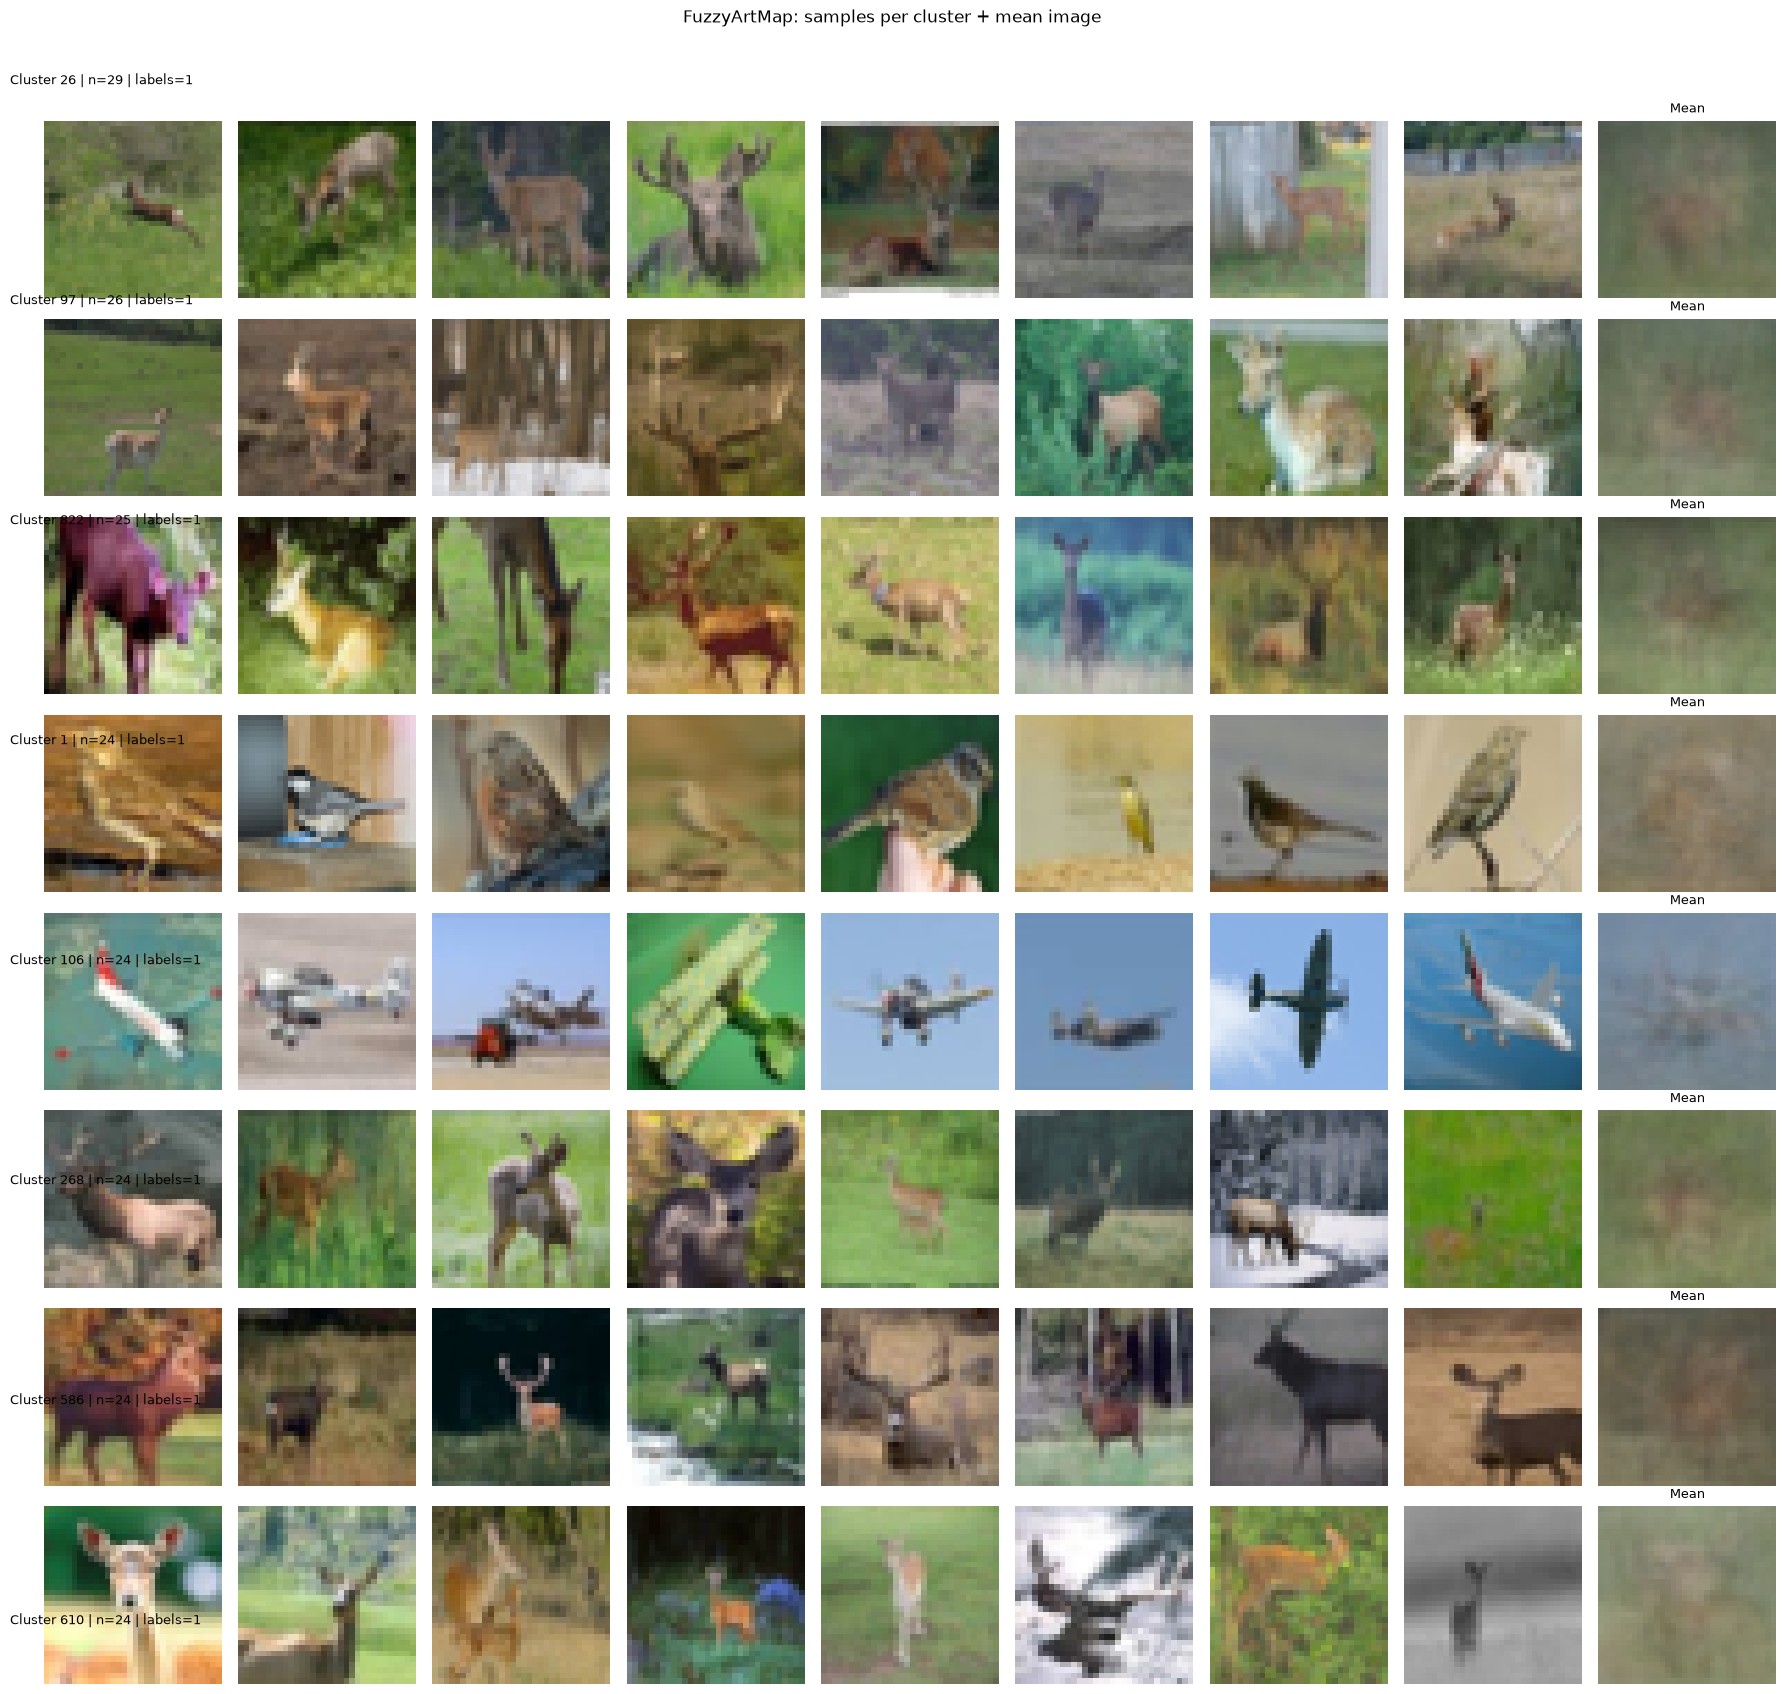

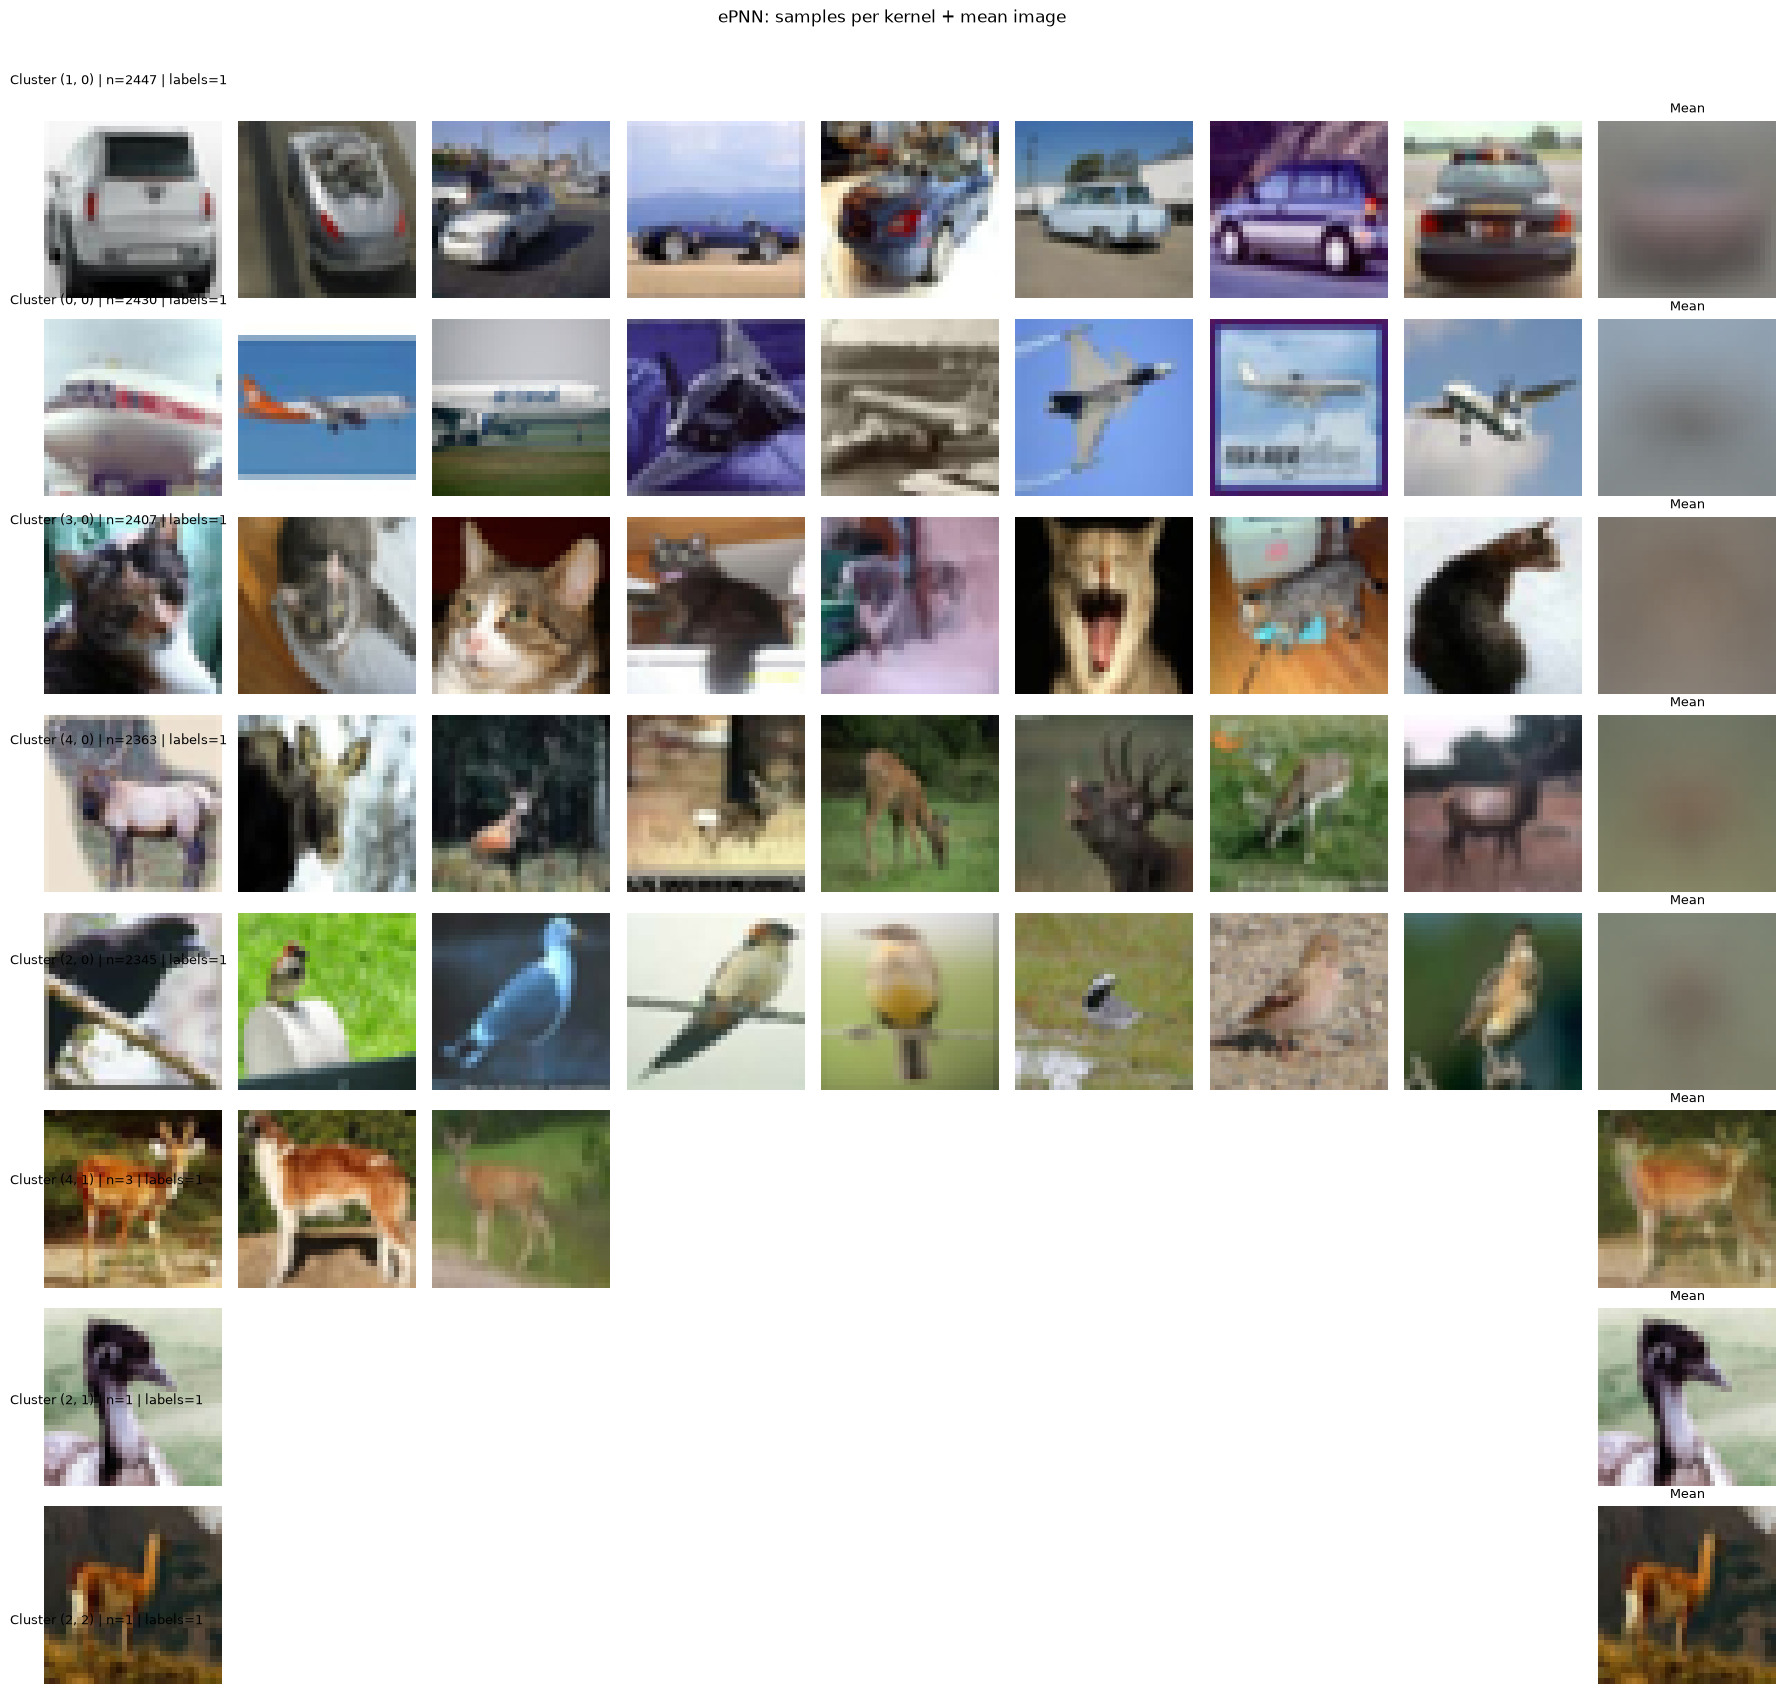

In [51]:
def plot_clusters_with_mean(images, cluster_ids, title, labels=None, max_clusters=8, samples_per_cluster=8):
    groups = {}
    label_array = None if labels is None else np.asarray(labels)
    for i, cid in enumerate(cluster_ids):
        if cid is None:
            continue
        if isinstance(cid, np.ndarray):
            cid = tuple(cid.tolist())
        elif isinstance(cid, list):
            cid = tuple(cid)
        groups.setdefault(cid, []).append(i)
    if not groups:
        print(f"No clusters found for {title}.")
        return
    scored_clusters = []
    for cid, idxs in groups.items():
        idxs = np.array(idxs)
        diversity = 0 if label_array is None else len(np.unique(label_array[idxs]))
        scored_clusters.append((cid, idxs, diversity, len(idxs)))
    scored_clusters.sort(key=lambda item: (-item[2], -item[3]))
    scored_clusters = scored_clusters[:max_clusters]
    cols = samples_per_cluster + 1
    rows = len(scored_clusters)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.0, rows * 2.2))
    if rows == 1:
        axes = np.array([axes])
    for row_idx, (cid, idxs, diversity, cluster_size) in enumerate(scored_clusters):
        n_show = min(samples_per_cluster, len(idxs))
        show_idx = np.random.choice(idxs, size=n_show, replace=False)
        for col in range(samples_per_cluster):
            ax = axes[row_idx, col]
            ax.axis("off")
            if col < n_show:
                ax.imshow(images[show_idx[col]].reshape(32, 32, 3))
        mean_img = images[idxs].mean(axis=0).reshape(32, 32, 3)
        ax_mean = axes[row_idx, -1]
        ax_mean.imshow(np.clip(mean_img, 0.0, 1.0))
        ax_mean.set_title("Mean", fontsize=9)
        ax_mean.axis("off")
        subtitle = f"Cluster {cid} | n={cluster_size}" if label_array is None else f"Cluster {cid} | n={cluster_size} | labels={diversity}"
        fig.text(0.01, (rows - row_idx - 0.5) / rows, subtitle, fontsize=9)
    plt.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0.02, 0.02, 1, 0.95])
    plt.show()


# ---- FuzzyArtMap clusters ----
plot_clusters_with_mean(
    X_train_half1,
    assignments_half1,
    labels=y_train_half1,
    title="FuzzyArtMap: samples per cluster + mean image",
    max_clusters=8,
    samples_per_cluster=8,
)

# ---- ePNN kernels (cluster = (class_label, kernel_index)) ----
def assign_epnn_kernels(net, X_epnn, y_labels):
    cluster_ids = []
    for i, x in enumerate(X_epnn):
        label = int(y_labels[i])
        gmm = net.gmms.get(label)
        if gmm is None or not gmm.kernels:
            cluster_ids.append(None)
            continue
        acts = [gmm._activation(x, k) * k.weight for k in gmm.kernels]
        k_idx = int(np.argmax(acts))
        cluster_ids.append((label, k_idx))
    return np.array(cluster_ids, dtype=object)

epnn_cluster_ids = assign_epnn_kernels(net_epnn, X_epnn_half1, y_train_half1)
plot_clusters_with_mean(
    X_train_half1,
    epnn_cluster_ids,
    labels=y_train_half1,
    title="ePNN: samples per kernel + mean image",
    max_clusters=8,
    samples_per_cluster=8,
)

### Training: 2nd half of classes 0 - 4

- Fuzzy Art Map

In [52]:
# -- Phase 2: FuzzyArtMap -- second half of classes 0-4 (incremental) ----
assignments_half2 = np.full(len(X_famap_half2), -1, dtype=np.int32)
for i in range(len(X_famap_half2)):
    assignments_half2[i] = net_famap.fit(X_famap_half2[i], int(y_train_half2[i]))

print(f"Active clusters after Phase 2: {len(net_famap.prototypes)}")

all_assignments_04 = np.concatenate([assignments_half1, assignments_half2])
all_y_train_04 = np.concatenate([y_train_half1, y_train_half2])

KeyboardInterrupt: 

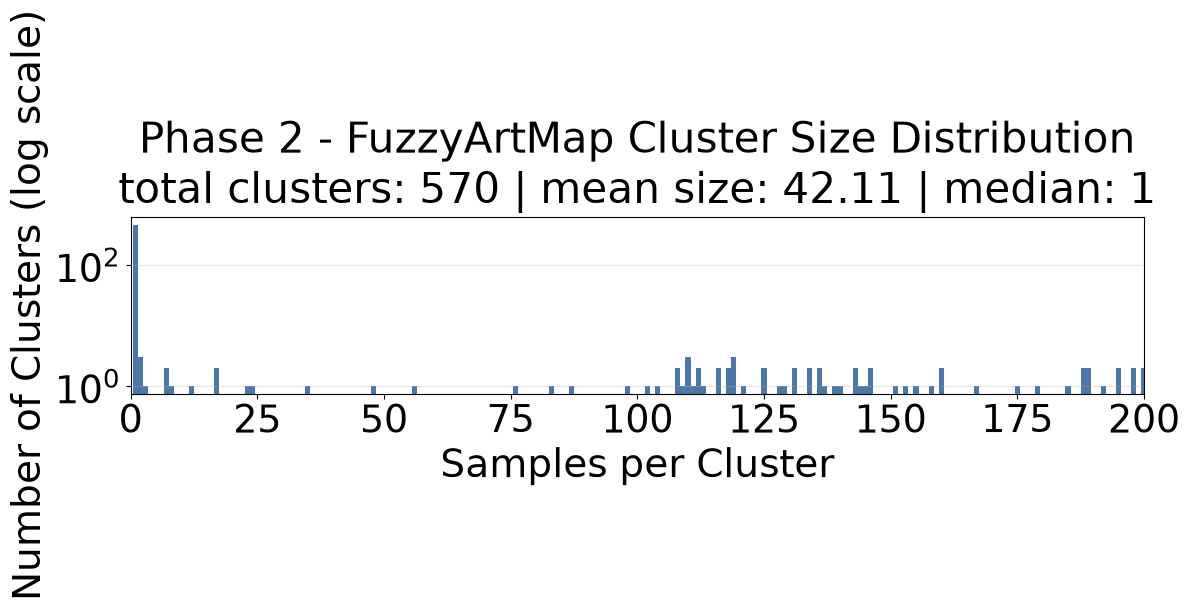

In [ ]:
plot_fuzzyart_cluster_sizes(all_assignments_04, "Phase 2 - FuzzyArtMap Cluster Size Distribution")

- ePNN

In [ ]:
# -- Phase 2: ePNN -- second half of classes 0-4 (incremental) -----------
for i in range(len(X_epnn_half2)):
    net_epnn.train(X_epnn_half2[i], int(y_train_half2[i]))

train_correct = sum(
    net_epnn.predict(X_epnn_half2[i]) == int(y_train_half2[i])
    for i in range(len(X_epnn_half2))
)
print(f"ePNN train accuracy (Phase 2, 2nd half): {train_correct / len(X_epnn_half2) * 100:.2f}% ({train_correct}/{len(X_epnn_half2)})")

ePNN train accuracy (Phase 2, 2nd half): 20.42% (2451/12000)


- MiniBatchKMeans

In [ ]:
# -- Phase 2: MiniBatchKMeans -- second half of classes 0-4 (incremental) -
t0 = time.time()
for digit in range(5):
    mask = y_train_half2 == digit
    X_digit = X_epnn_half2[mask]
    kmeans_models[digit].partial_fit(X_digit)

dt = time.time() - t0
print(f"MiniBatchKMeans Phase 2 done in {dt:.2f}s")

MiniBatchKMeans Phase 2 done in 0.01s


- MLP

In [ ]:
# -- Phase 2: MLP -- second half of classes 0-4 (incremental) ------------
t0 = time.time()
train_mlp_phase(net_mlp, X_epnn_half2, y_train_half2, seed=43)
dt = time.time() - t0

train_acc = np.mean(net_mlp.predict(X_epnn_half2) == y_train_half2)
print(f"MLP Phase 2 done in {dt:.2f}s")
print(f"MLP train accuracy (Phase 2, 2nd half): {train_acc * 100:.2f}%")

MLP Phase 2 done in 7.06s
MLP train accuracy (Phase 2, 2nd half): 93.98%


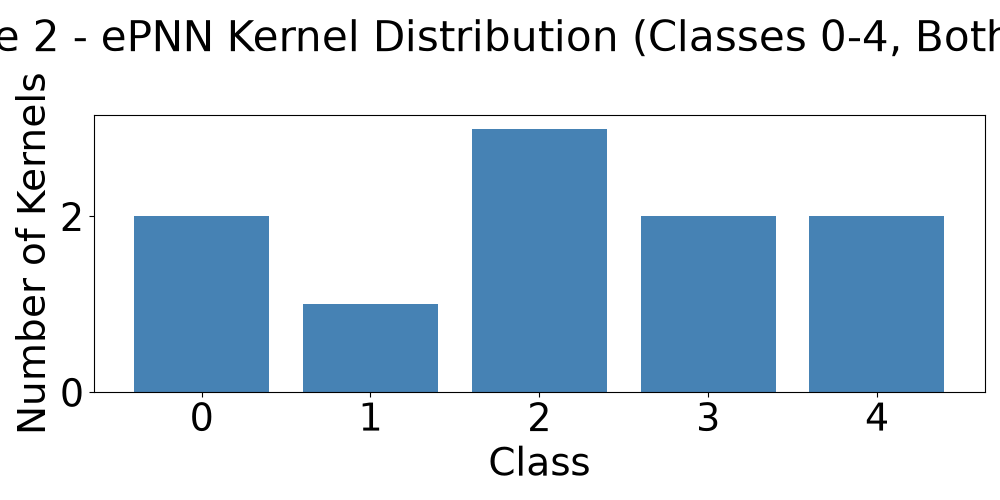

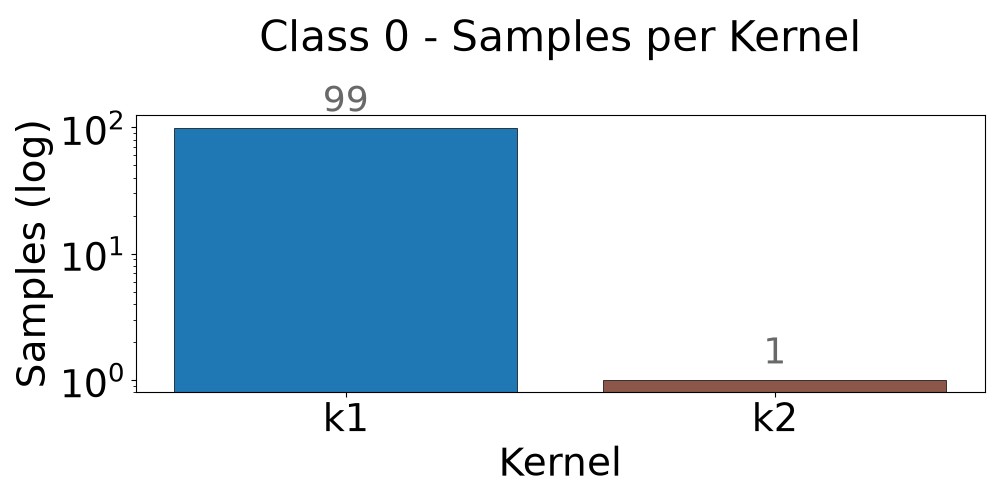

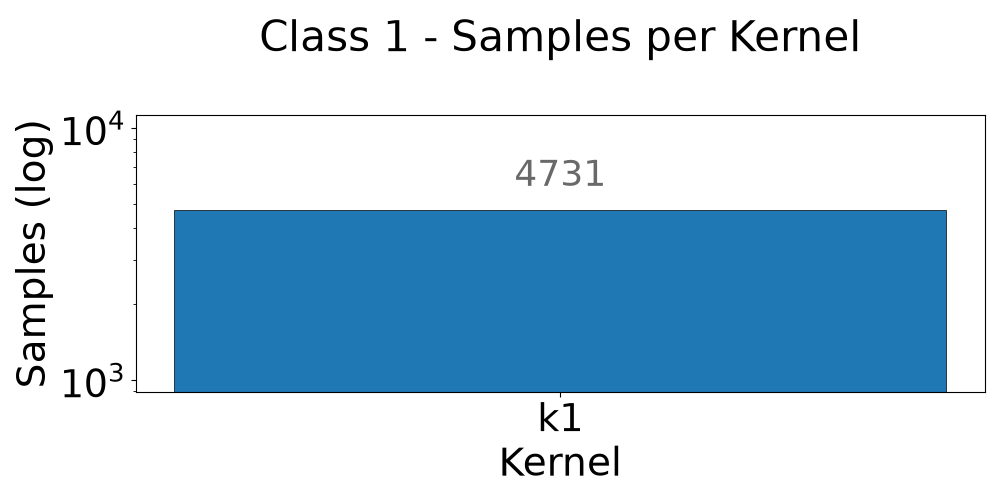

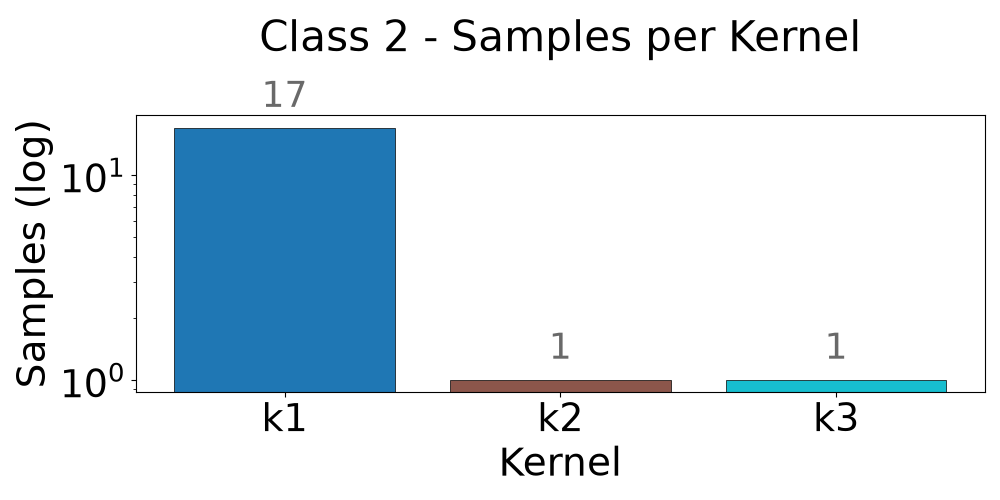

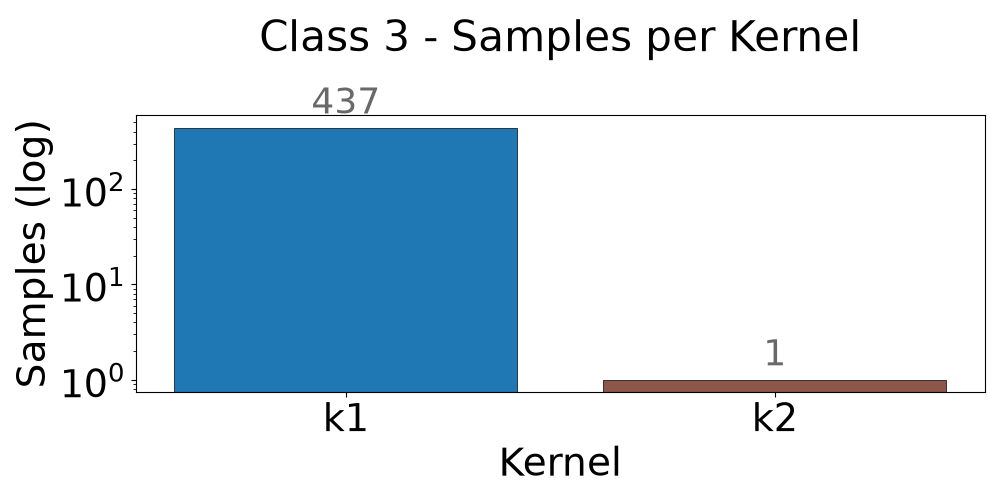

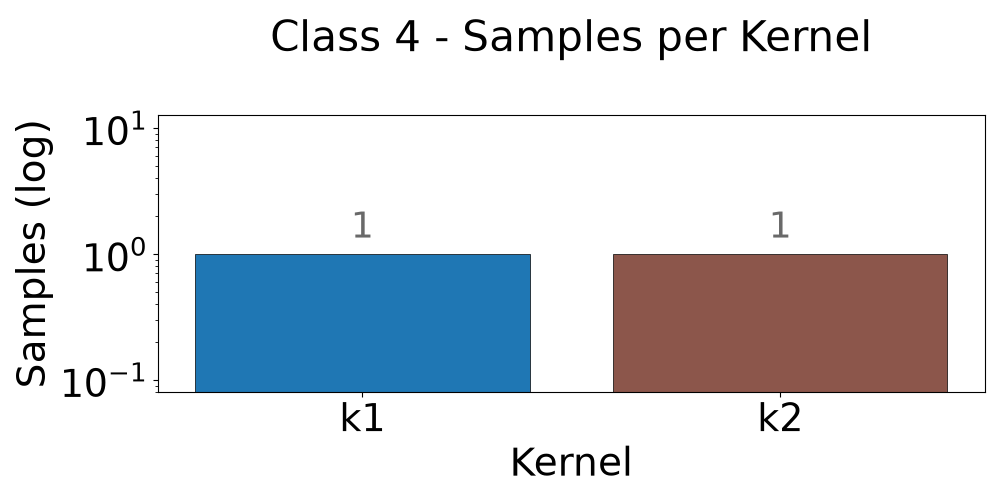

In [ ]:
plot_epnn_kernels(net_epnn, title="Phase 2 - ePNN Kernel Distribution (Classes 0-4, Both Halves)")

### Testing and comparing the models

In [ ]:
# -- Phase 2: Evaluation --------------------------------------------------
fuzzy_preds_2 = predict_famap(net_famap, X_famap_test_04)
epnn_preds_2 = predict_epnn(net_epnn, X_epnn_test_04)
kmeans_preds_2 = predict_kmeans(kmeans_models, X_epnn_test_04)
mlp_preds_2 = net_mlp.predict(X_epnn_test_04)

print_comparison(
    {"ePNN": epnn_preds_2, "FuzzyArtMap": fuzzy_preds_2, "MiniBatchKMeans": kmeans_preds_2, "MLP": mlp_preds_2},
    y_test_04, list(range(5)),
    "Phase 2 - Second Half (Classes 0-4, Incremental)"
)


  Phase 2 - Second Half (Classes 0-4, Incremental)

Aggregate (macro-average):
          Model Accuracy Precision Recall F1-score
           ePNN    20.6%    26.58%  20.6%     7.9%
    FuzzyArtMap   29.28%    29.52% 29.28%   29.24%
MiniBatchKMeans   50.43%    54.38% 50.43%   49.81%
            MLP   61.92%    62.01% 61.92%   61.95%

Per-class metrics:
          Model  Class Precision Recall F1-score  Support
           ePNN      0    80.95%  1.42%    2.78%     1200
           ePNN      1    20.28% 100.0%   33.72%     1200
           ePNN      2      0.0%   0.0%     0.0%     1200
           ePNN      3    31.67%  1.58%    3.02%     1200
           ePNN      4      0.0%   0.0%     0.0%     1200
    FuzzyArtMap      0    30.08% 33.08%   31.51%     1200
    FuzzyArtMap      1    36.74% 29.67%   32.83%     1200
    FuzzyArtMap      2    25.54% 21.67%   23.44%     1200
    FuzzyArtMap      3    27.19% 30.58%   28.78%     1200
    FuzzyArtMap      4    28.07% 31.42%   29.65%     1200
MiniBat

### Training: Adding classes 5 - 9

- Fuzzy Art Map

In [ ]:
# -- Phase 3: FuzzyArtMap -- new classes 5-9 (incremental) ---------------
assignments_59 = np.full(len(X_famap_train_59), -1, dtype=np.int32)
for i in range(len(X_famap_train_59)):
    assignments_59[i] = net_famap.fit(X_famap_train_59[i], int(y_train_59[i]))

print(f"Active clusters after Phase 3: {len(net_famap.prototypes)}")

all_assignments = np.concatenate([all_assignments_04, assignments_59])
all_y_train = np.concatenate([all_y_train_04, y_train_59])

Active clusters after Phase 3: 1688


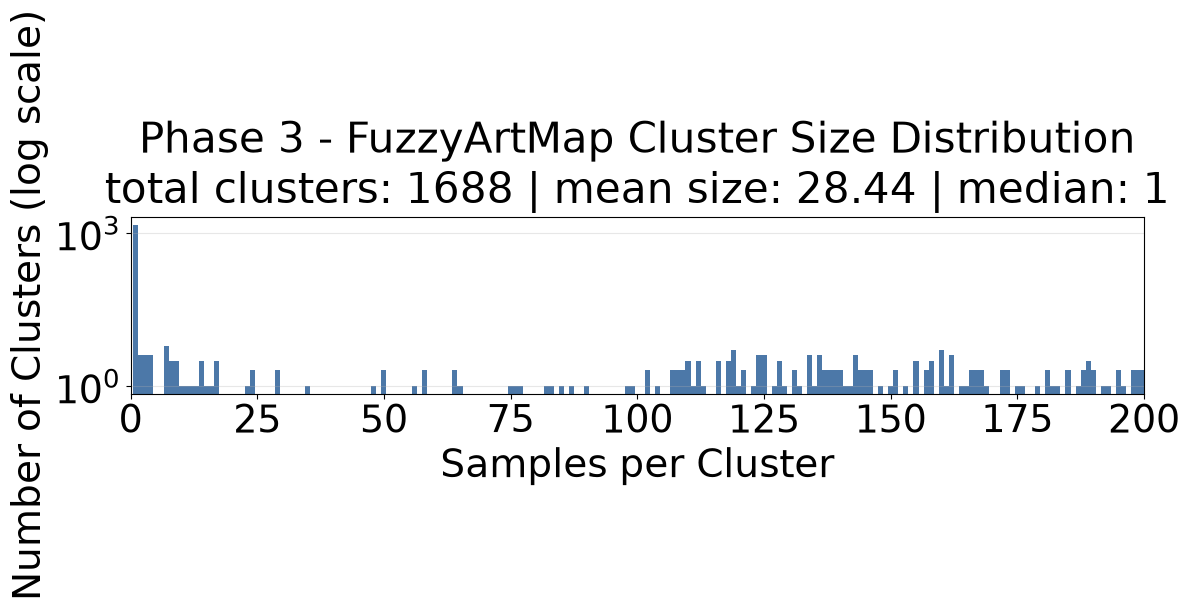

In [ ]:
plot_fuzzyart_cluster_sizes(all_assignments, "Phase 3 - FuzzyArtMap Cluster Size Distribution")

- ePNN

In [ ]:
# -- Phase 3: ePNN -- new classes 5-9 (incremental) ----------------------
for i in range(len(X_epnn_train_59)):
    net_epnn.train(X_epnn_train_59[i], int(y_train_59[i]))

train_correct = sum(
    net_epnn.predict(X_epnn_train_59[i]) == int(y_train_59[i])
    for i in range(len(X_epnn_train_59))
)
print(f"ePNN train accuracy (Phase 3, classes 5-9): {train_correct / len(X_epnn_train_59) * 100:.2f}% ({train_correct}/{len(X_epnn_train_59)})")

ePNN train accuracy (Phase 3, classes 5-9): 20.10% (4825/24000)


- MiniBatchKMeans

In [ ]:
# -- Phase 3: MiniBatchKMeans -- new classes 5-9 (incremental) -----------
t0 = time.time()
for digit in range(5, 10):
    mask = y_train_59 == digit
    X_digit = X_epnn_train_59[mask]
    kmeans_models[digit] = MiniBatchKMeans(n_clusters=N_CLUSTERS_PER_CLASS, n_init=5, random_state=42)
    kmeans_models[digit].fit(X_digit)

dt = time.time() - t0
print(f"MiniBatchKMeans Phase 3 done in {dt:.2f}s")
print(f"Models trained for classes: {sorted(kmeans_models.keys())}")

MiniBatchKMeans Phase 3 done in 0.41s
Models trained for classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


- MLP

In [ ]:
# -- Phase 3: MLP -- new classes 5-9 (incremental) -----------------------
t0 = time.time()
train_mlp_phase(net_mlp, X_epnn_train_59, y_train_59, seed=44)
dt = time.time() - t0

train_acc = np.mean(net_mlp.predict(X_epnn_train_59) == y_train_59)
print(f"MLP Phase 3 done in {dt:.2f}s")
print(f"MLP train accuracy (Phase 3, classes 5-9): {train_acc * 100:.2f}%")

MLP Phase 3 done in 3.62s
MLP train accuracy (Phase 3, classes 5-9): 91.20%


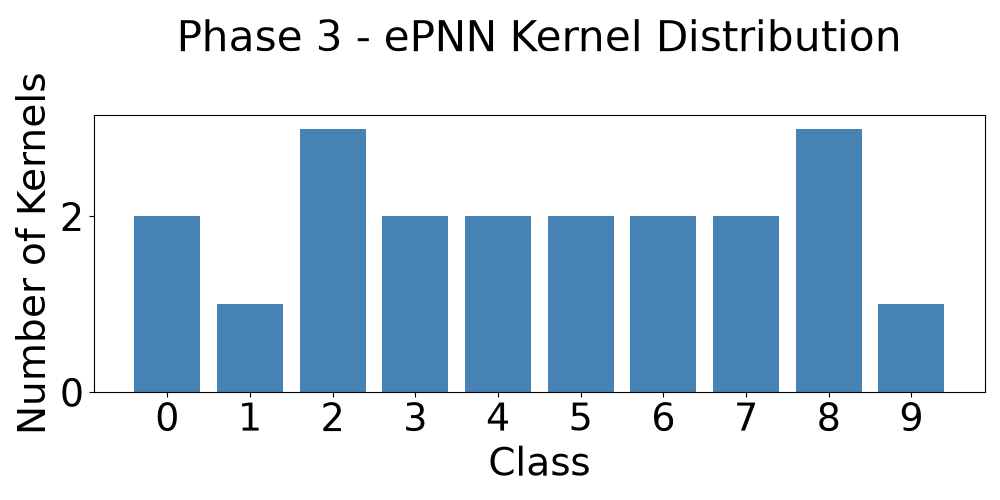

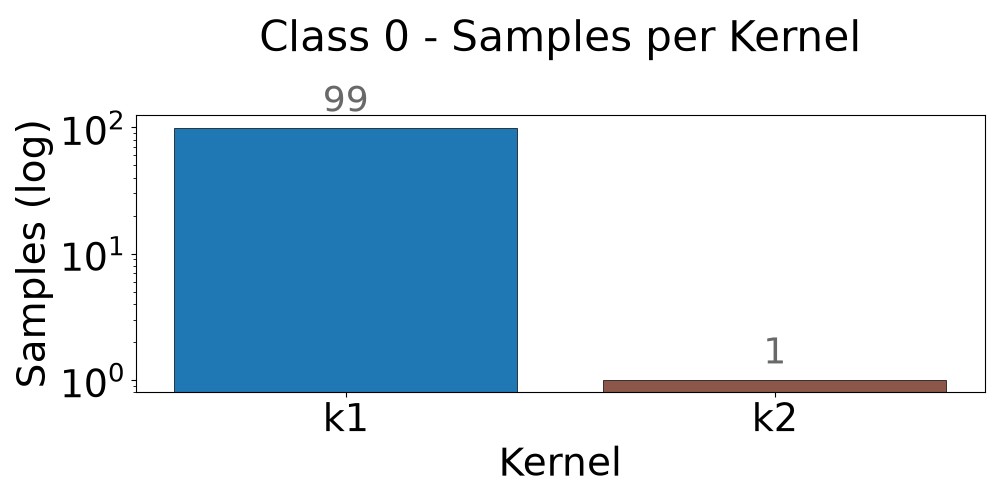

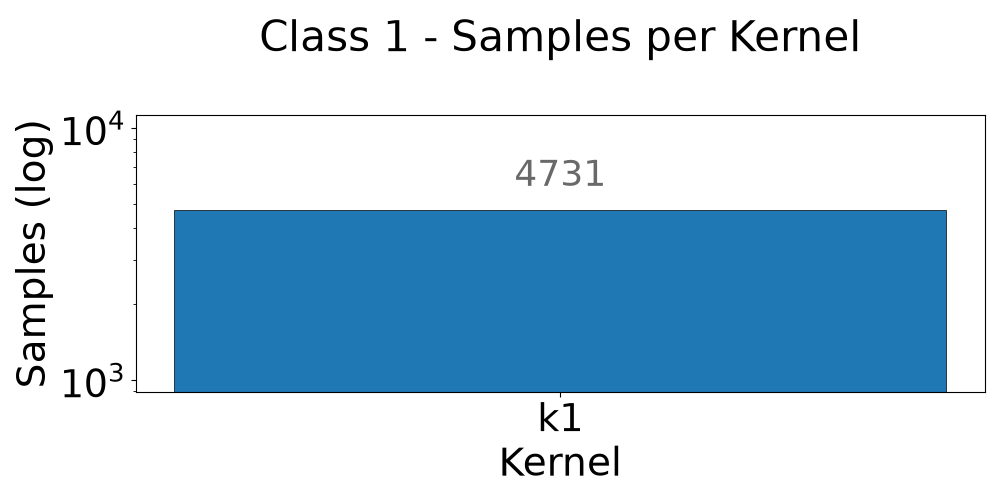

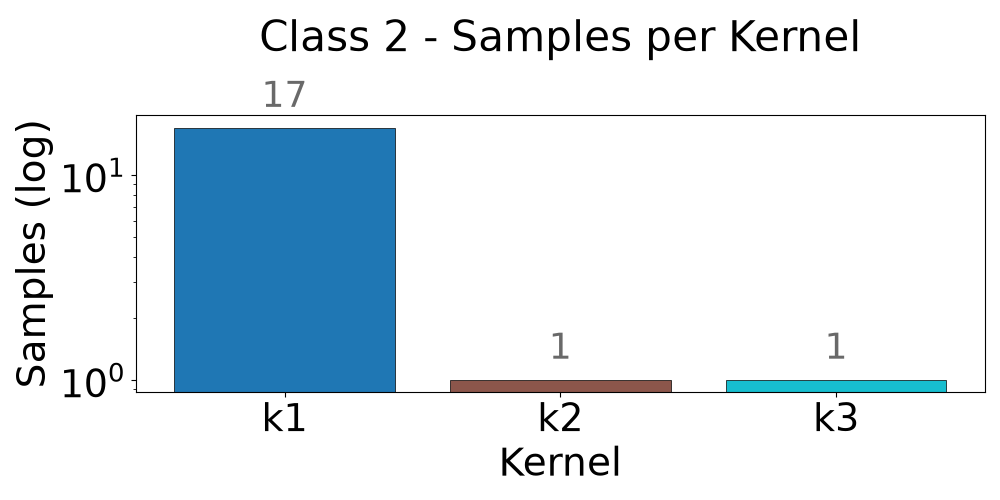

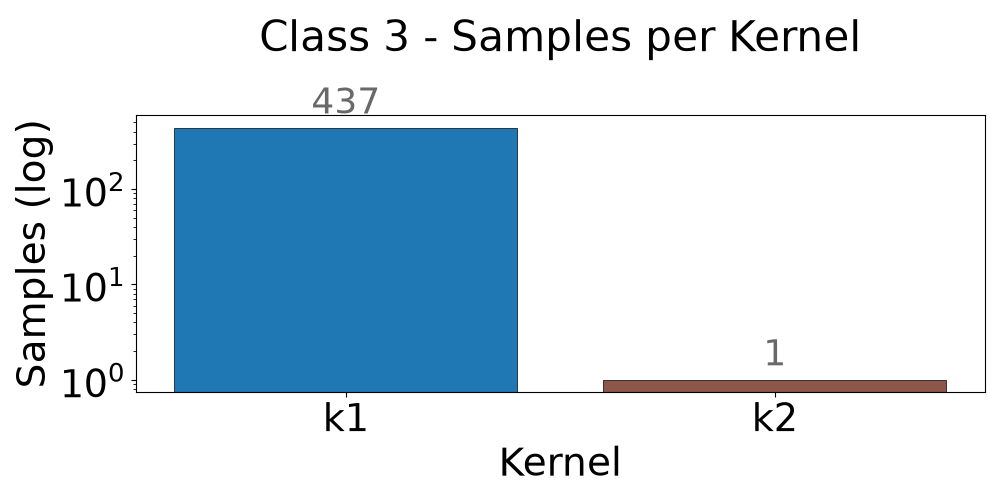

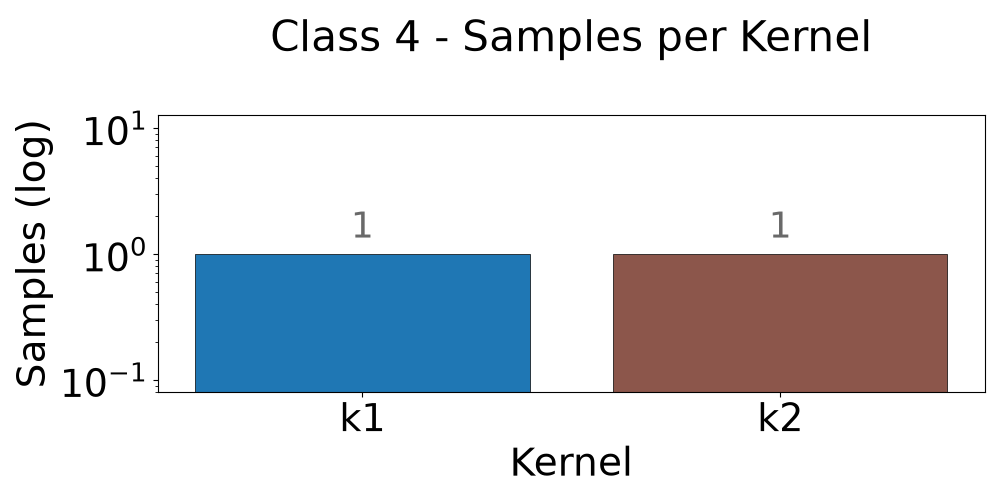

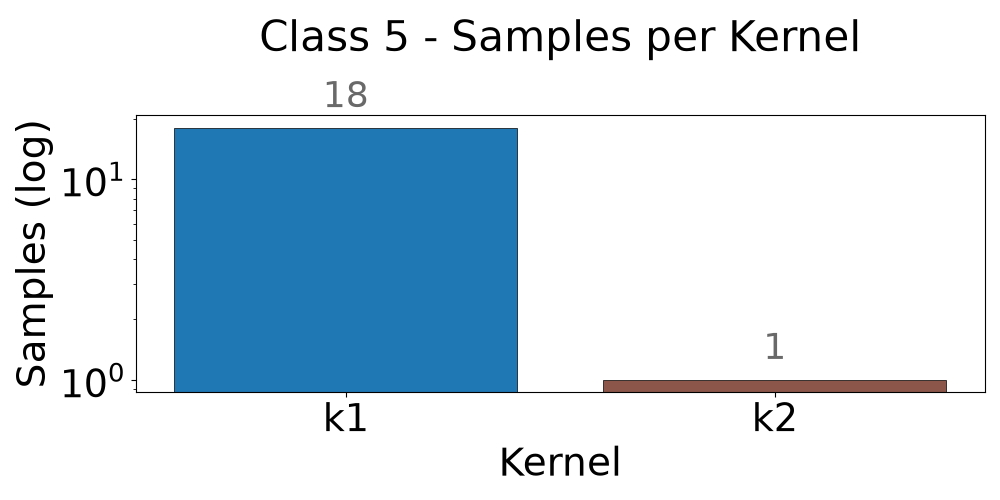

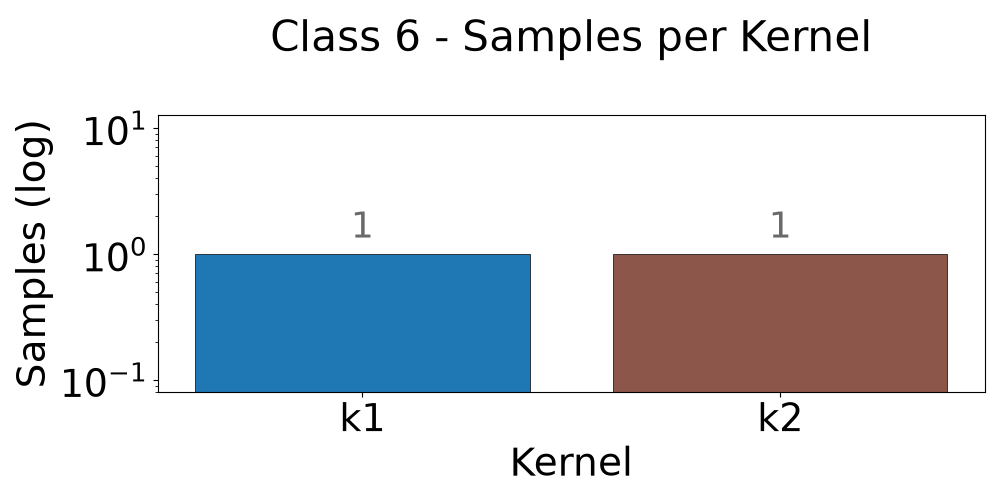

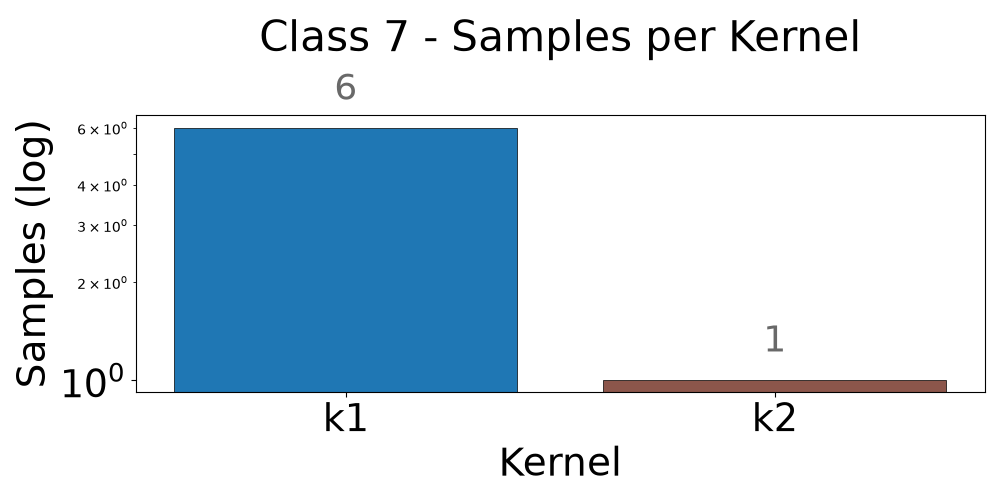

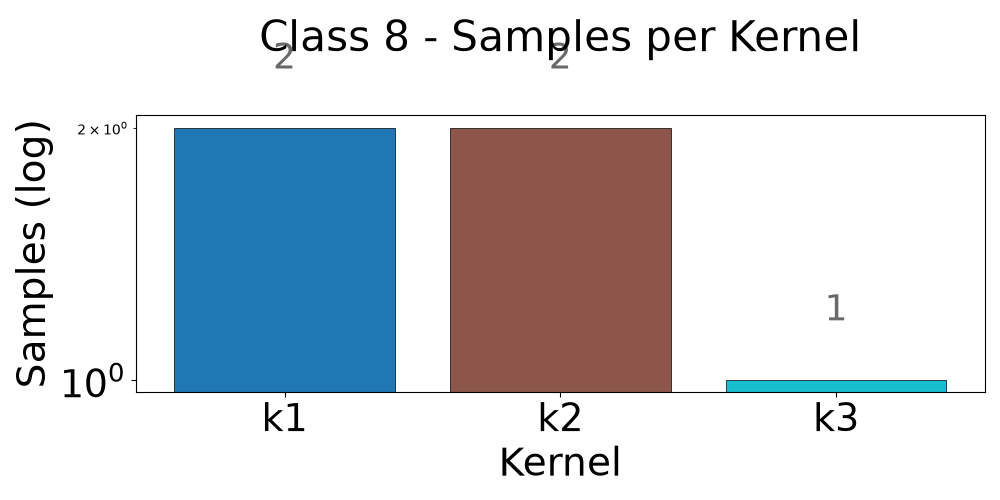

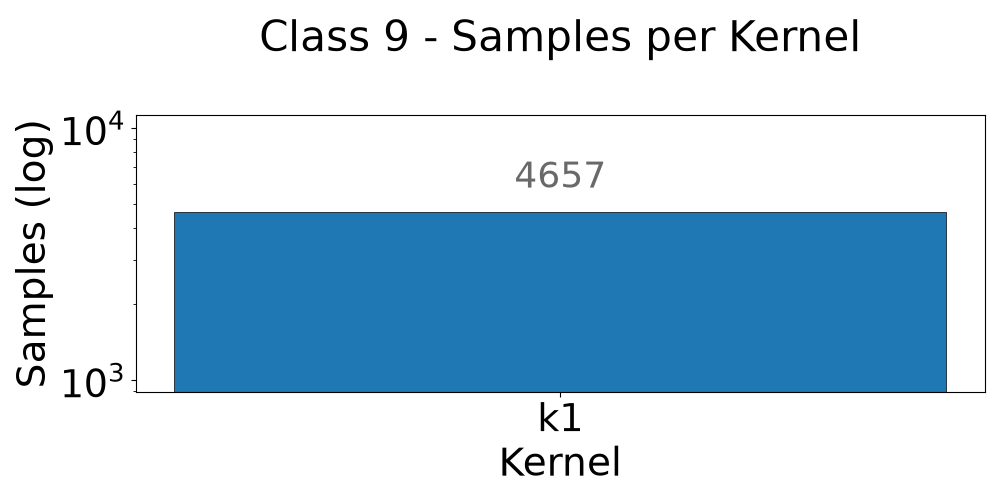

In [ ]:
plot_epnn_kernels(net_epnn, title="Phase 3 - ePNN Kernel Distribution")

### Testing and comparing the models

In [ ]:
# -- Phase 3: Evaluation --------------------------------------------------
fuzzy_preds_3_04 = predict_famap(net_famap, X_famap_test_04)
epnn_preds_3_04 = predict_epnn(net_epnn, X_epnn_test_04)
kmeans_preds_3_04 = predict_kmeans(kmeans_models, X_epnn_test_04)
mlp_preds_3_04 = net_mlp.predict(X_epnn_test_04)

print_comparison(
    {"ePNN": epnn_preds_3_04, "FuzzyArtMap": fuzzy_preds_3_04, "MiniBatchKMeans": kmeans_preds_3_04, "MLP": mlp_preds_3_04},
    y_test_04, list(range(0, 5)),
    "Phase 3 - Known Classes (0-4)"
)

fuzzy_preds_3_59 = predict_famap(net_famap, X_famap_test_59)
epnn_preds_3_59 = predict_epnn(net_epnn, X_epnn_test_59)
kmeans_preds_3_59 = predict_kmeans(kmeans_models, X_epnn_test_59)
mlp_preds_3_59 = net_mlp.predict(X_epnn_test_59)

print_comparison(
    {"ePNN": epnn_preds_3_59, "FuzzyArtMap": fuzzy_preds_3_59, "MiniBatchKMeans": kmeans_preds_3_59, "MLP": mlp_preds_3_59},
    y_test_59, list(range(5, 10)),
    "Phase 3 - New Classes (5-9, Incremental)"
)

KeyboardInterrupt: 

### Training and testing MiniBatchKMeans with the whole dataset

In [ ]:
import time
import numpy as np
from sklearn.cluster import MiniBatchKMeans

data = {}

t0 = time.time()

for i in range(10):
    data[i] = {
        "images": np.array([img for img, lbl in zip(X_train, y_train) if lbl == i]),
        "clusters": MiniBatchKMeans(n_clusters=15, n_init=5),
    }
    data[i]['clusters'].fit(data[i]['images'])

dt = time.time() - t0
print("done in %.2fs." % dt)

done in 16.39s.


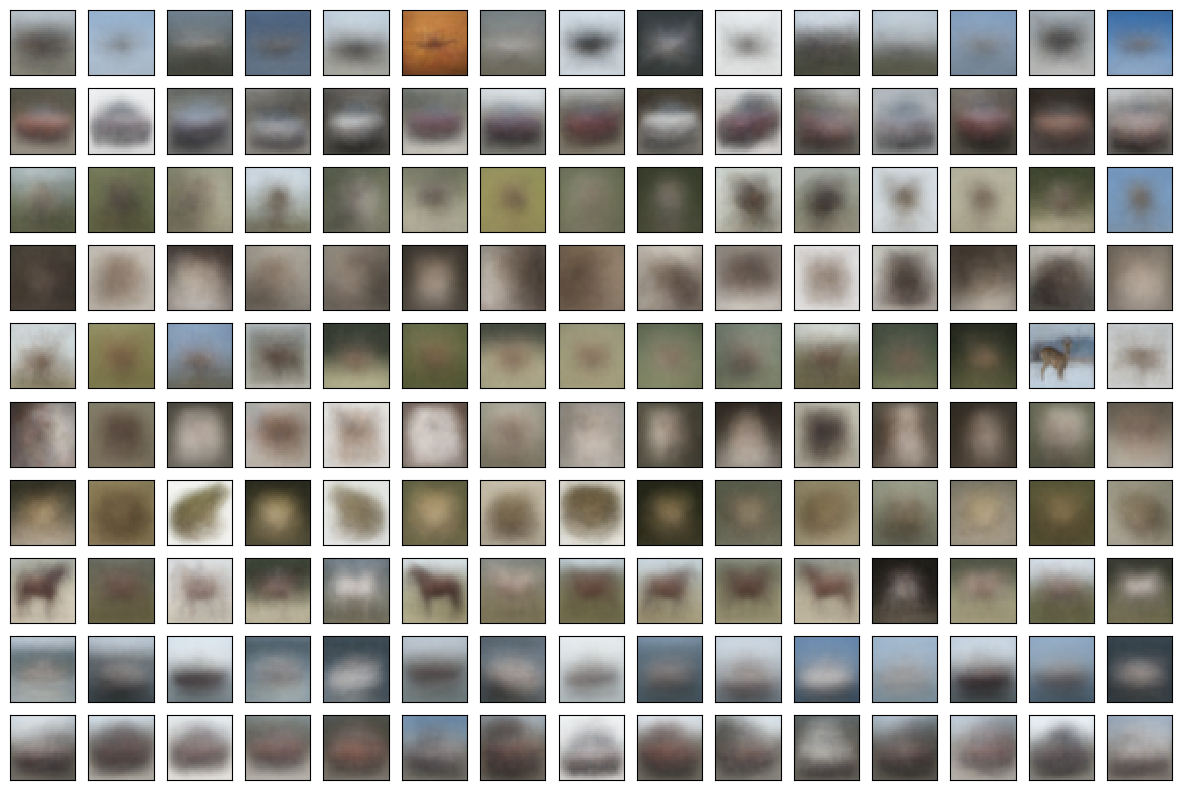

In [ ]:
plt.close('all')
plt.figure(figsize=(15, 10))
for lbl in range(10):
    cluters = data[lbl]['clusters']
    for c_idx in range(len(cluters.cluster_centers_)):
        plt.subplot(10, 15, lbl * 15 + c_idx + 1)
        plt.imshow(np.clip(cluters.cluster_centers_[c_idx].reshape((32, 32, 3)), 0.0, 1.0), interpolation="nearest")
        plt.xticks(())
        plt.yticks(())

plt.show()

In [ ]:
from sklearn.metrics import classification_report

prd = []
true = []

for img, true_lbl in zip(X_test, y_test):
    true.append(true_lbl)
    min_dist = np.inf
    prd_lbl = -1
    for lbl in range(10):
        for c in data[lbl]['clusters'].cluster_centers_:
            d = np.linalg.norm(img - c)
            if d < min_dist:
                min_dist = d
                prd_lbl = lbl
    prd.append(prd_lbl)

print(classification_report(true, prd))

              precision    recall  f1-score   support

           0       0.39      0.38      0.38      1200
           1       0.35      0.35      0.35      1200
           2       0.22      0.23      0.22      1200
           3       0.20      0.20      0.20      1200
           4       0.25      0.25      0.25      1200
           5       0.30      0.30      0.30      1200
           6       0.31      0.36      0.34      1200
           7       0.36      0.32      0.34      1200
           8       0.45      0.43      0.44      1200
           9       0.38      0.37      0.38      1200

    accuracy                           0.32     12000
   macro avg       0.32      0.32      0.32     12000
weighted avg       0.32      0.32      0.32     12000



In [ ]:
n = 40
pca_ = PCA(n_components=n, random_state=42)
scaler_ = StandardScaler()

# Fit on the whole training set; transform test with the same transform
X_train = scaler_.fit_transform(pca_.fit_transform(X_train))
X_test = scaler_.transform(pca_.transform(X_test))

In [ ]:
epnn = ePNN(
    n_max=500,
    phi_init=0.30,
    t=0.0,
    alpha=0.005,
    fac=1.2,
    s=0.5,
)

for i in range(len(X_train)):
    epnn.train(X_train[i], int(y_train[i]))

train_corr = sum(
    epnn.predict(X_train[i]) == int(y_train[i])
    for i in range(len(X_train))
)
print(f"ePNN train accuracy: {train_corr / len(X_train) * 100:.2f}% ({train_corr}/{len(X_train)})")

ePNN train accuracy: 21.23% (10191/48000)


In [ ]:
preds = predict_epnn(epnn, X_test)
report = classification_report(y_test, preds)
print(report)

              precision    recall  f1-score   support

           0       0.35      0.30      0.32      1200
           1       0.00      0.00      0.00      1200
           2       0.22      0.27      0.24      1200
           3       0.00      0.00      0.00      1200
           4       0.51      0.06      0.10      1200
           5       0.13      0.68      0.21      1200
           6       0.26      0.34      0.30      1200
           7       0.00      0.00      0.00      1200
           8       0.39      0.44      0.41      1200
           9       0.00      0.00      0.00      1200

    accuracy                           0.21     12000
   macro avg       0.19      0.21      0.16     12000
weighted avg       0.19      0.21      0.16     12000



/home/salatiel/code/tcc/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/salatiel/code/tcc/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/salatiel/code/tcc/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

- MLP

In [ ]:
# -- MLP -- whole dataset -------------------------------------------------
from sklearn.neural_network import MLPClassifier

net_mlp_full = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation="relu",
    solver="adam",
    learning_rate_init=1e-3,
    random_state=42,
    max_iter=200,
)

t0 = time.time()
net_mlp_full.fit(X_train, y_train)
dt = time.time() - t0

train_acc = net_mlp_full.score(X_train, y_train)
print(f"MLP whole-dataset training done in {dt:.2f}s")
print(f"MLP train accuracy: {train_acc * 100:.2f}%")

MLP whole-dataset training done in 30.63s
MLP train accuracy: 58.25%


/home/salatiel/code/tcc/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
mlp_preds_full = net_mlp_full.predict(X_test)
report = classification_report(y_test, mlp_preds_full)
print(report)

              precision    recall  f1-score   support

           0       0.59      0.55      0.57      1200
           1       0.59      0.63      0.61      1200
           2       0.39      0.36      0.37      1200
           3       0.35      0.34      0.34      1200
           4       0.42      0.47      0.45      1200
           5       0.46      0.34      0.39      1200
           6       0.49      0.58      0.53      1200
           7       0.56      0.55      0.55      1200
           8       0.61      0.69      0.65      1200
           9       0.56      0.55      0.56      1200

    accuracy                           0.51     12000
   macro avg       0.50      0.51      0.50     12000
weighted avg       0.50      0.51      0.50     12000



### Comparing all models - whole dataset

In [ ]:
# -- Whole dataset -- unified comparison ----------------------------------
print_comparison(
    {"MiniBatchKMeans": np.array(prd), "ePNN": preds, "MLP": mlp_preds_full},
    y_test, list(range(10)),
    "Whole Dataset - Model Comparison"
)


  Whole Dataset - Model Comparison

Aggregate (macro-average):
          Model Accuracy Precision Recall F1-score
MiniBatchKMeans   31.91%    32.08% 31.91%   31.96%
           ePNN   20.89%    18.55% 20.89%    15.9%
            MLP   50.54%    50.31% 50.54%   50.24%

Per-class metrics:
          Model  Class Precision Recall F1-score  Support
MiniBatchKMeans      0    38.76%  37.5%   38.12%     1200
MiniBatchKMeans      1    35.14% 34.67%    34.9%     1200
MiniBatchKMeans      2    21.96%  23.0%   22.47%     1200
MiniBatchKMeans      3    20.37% 20.08%   20.23%     1200
MiniBatchKMeans      4    25.08% 25.25%   25.17%     1200
MiniBatchKMeans      5    29.66% 29.58%   29.62%     1200
MiniBatchKMeans      6    31.15%  36.5%   33.61%     1200
MiniBatchKMeans      7    35.78% 32.08%   33.83%     1200
MiniBatchKMeans      8    44.74% 43.25%   43.98%     1200
MiniBatchKMeans      9    38.18% 37.17%   37.67%     1200
           ePNN      0    34.54% 30.33%    32.3%     1200
           ePNN 

In [ ]:
# -- Vigilance sweep: accuracy vs cluster count (FuzzyArtMap) ------------
# vigilance_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
vigilance_values = [0.9, 0.95, 0.99, 0.999]
sweep_results = {}

for v in vigilance_values:
    net_v = FuzzyArtMap(
        vigilance=v,
        lr=0.5,
        use_complement_coding=True,
        epsilon=1e-3,
    )
    v_assignments = np.array(
        [net_v.fit(x, int(y)) for x, y in zip(X_famap_half1, y_train_half1)],
        dtype=np.int32,
    )

    correct = sum(
        net_v.predict(x) == y_test_04[i]
        for i, x in enumerate(X_famap_test_04)
    )
    counts = np.array([np.sum(v_assignments == cid) for cid in np.unique(v_assignments)])
    sweep_results[v] = {
        "num_clusters": len(net_v.prototypes),
        "mean_cluster_size": float(np.mean(counts)) if len(counts) else 0.0,
        "accuracy": correct / len(X_famap_test_04),
    }

print("Vigilance | Clusters | Mean size | Accuracy")
for v, r in sweep_results.items():
    print(f"  {v:.2f}  |  {r['num_clusters']:6d}  |  {r['mean_cluster_size']:7.2f}  |  {r['accuracy'] * 100:.2f}%")

# Vigilance vs clusters
from matplotlib.ticker import FuncFormatter, NullLocator


def declutter_log_ticks(values, min_ratio=1.15):
    """Dedup + drop values too close together in log-space so labels don't overlap."""
    vals = sorted(set(values))
    kept = [vals[0]]
    for v in vals[1:]:
        if v / kept[-1] >= min_ratio:
            kept.append(v)
    if kept[-1] != vals[-1] and vals[-1] / kept[-1] < min_ratio:
        kept[-1] = vals[-1]
    return kept


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
vs = list(sweep_results.keys())
ncs = [sweep_results[v]["num_clusters"] for v in vs]
mcs = [sweep_results[v]["mean_cluster_size"] for v in vs]
accs = [sweep_results[v]["accuracy"] for v in vs]

axes[0].plot(vs, ncs, marker="o")
axes[0].set_yscale("log")
axes[0].set_xlabel("Vigilance"); axes[0].set_ylabel("Clusters (log)"); axes[0].set_title("Clusters vs Vigilance")
axes[0].grid(True, which="both", alpha=0.3)
axes[0].set_yticks(declutter_log_ticks(ncs))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{int(round(y))}"))
axes[0].yaxis.set_minor_locator(NullLocator())
axes[0].tick_params(axis="y", labelsize=8)

axes[1].plot(vs, mcs, marker="o")
axes[1].set_yscale("log")
axes[1].set_xlabel("Vigilance"); axes[1].set_ylabel("Mean samples/cluster (log)"); axes[1].set_title("Cluster Size vs Vigilance")
axes[1].grid(True, which="both", alpha=0.3)
axes[1].set_yticks(declutter_log_ticks(np.round(mcs, 2)))
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.1f}"))
axes[1].yaxis.set_minor_locator(NullLocator())
axes[1].tick_params(axis="y", labelsize=8)

axes[2].plot(ncs, accs, marker="o", color="#E45756")
for v, nc, acc in zip(vs, ncs, accs):
    axes[2].annotate(f"v={v:.2f}", (nc, acc), textcoords="offset points", xytext=(5, 5), fontsize=7)
axes[2].set_xscale("log")
axes[2].set_xlabel("Clusters (log)"); axes[2].set_ylabel("Accuracy"); axes[2].set_title("Accuracy vs Clusters")
axes[2].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

NameError: name 'FuzzyArtMap' is not defined

### Multi-seed experiment (10 seeds)

The cells above run the full three-phase incremental pipeline once, with a
fixed `random_state=42`. The section below repeats that **same experiment**
over 10 different random seeds so the results can be reported as a
mean +/- standard deviation rather than a single run.

For each seed, every source of randomness is derived from that seed - the
train/test split and its shuffling, the split into first/second halves, PCA,
MiniBatchKMeans, the MLP weight initialization and its per-epoch shuffling -
so each seed is an independent replication of the experiment. The four models
(FuzzyArtMap, ePNN, MiniBatchKMeans, MLP) and their hyperparameters are
identical to the single-seed run above.

> **Note:** ePNN and FuzzyArtMap train sample-by-sample in pure Python over
> tens of thousands of samples per seed, so all 10 seeds can take a long time
> to finish. Reduce `SEEDS` while iterating if needed.

In [ ]:
# -- Multi-seed experiment: repeat the full 3-phase pipeline over many seeds --
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.neural_network import MLPClassifier

# Same hyperparameters as the single-seed experiment above.
N_COMPONENTS = 40
N_CLUSTERS_PER_CLASS = 15


def run_experiment(seed):
    """Run the full incremental experiment once with a given random seed and
    return a list of metric records (one per model / phase / evaluation group).

    All randomness - the train/test split, the half split, PCA, MiniBatchKMeans,
    the MLP init and its per-epoch shuffling - is derived from `seed`, so each
    seed is an independent replication of the experiment."""

    # -- Data: classes 0-4 (phases 1 & 2) and 5-9 (phase 3), shuffled by seed --
    mask_04 = (cifar_y >= 0) & (cifar_y <= 4)
    X_04, y_04 = cifar_X[mask_04], cifar_y[mask_04]
    Xtr_04, Xte_04, ytr_04, yte_04 = train_test_split(
        X_04, y_04, test_size=0.2, random_state=seed, stratify=y_04
    )
    mid = len(Xtr_04) // 2
    Xtr_h1, ytr_h1 = Xtr_04[:mid], ytr_04[:mid]
    Xtr_h2, ytr_h2 = Xtr_04[mid:], ytr_04[mid:]

    mask_59 = (cifar_y >= 5) & (cifar_y <= 9)
    X_59, y_59 = cifar_X[mask_59], cifar_y[mask_59]
    Xtr_59, Xte_59, ytr_59, yte_59 = train_test_split(
        X_59, y_59, test_size=0.2, random_state=seed, stratify=y_59
    )

    # -- Feature transforms (fit on the first half only, as in the base run) --
    pca = PCA(n_components=N_COMPONENTS, random_state=seed)
    scaler = StandardScaler()
    Xe_h1 = scaler.fit_transform(pca.fit_transform(Xtr_h1))
    Xe_h2 = scaler.transform(pca.transform(Xtr_h2))
    Xe_tr59 = scaler.transform(pca.transform(Xtr_59))
    Xe_te04 = scaler.transform(pca.transform(Xte_04))
    Xe_te59 = scaler.transform(pca.transform(Xte_59))

    minmax = MinMaxScaler()
    Xf_h1 = np.clip(minmax.fit_transform(pca.transform(Xtr_h1)), 0.0, 1.0)
    Xf_h2 = np.clip(minmax.transform(pca.transform(Xtr_h2)), 0.0, 1.0)
    Xf_tr59 = np.clip(minmax.transform(pca.transform(Xtr_59)), 0.0, 1.0)
    Xf_te04 = np.clip(minmax.transform(pca.transform(Xte_04)), 0.0, 1.0)
    Xf_te59 = np.clip(minmax.transform(pca.transform(Xte_59)), 0.0, 1.0)

    # -- Models (fresh per seed) ----------------------------------------------
    famap = FuzzyArtMap(vigilance=0.5, lr=0.5, use_complement_coding=True, epsilon=1e-3)
    epnn = ePNN(n_max=500, phi_init=0.50, t=0.0, alpha=0.05, fac=1.2, s=0.5)
    kmeans_models = {}
    mlp = MLPClassifier(
        hidden_layer_sizes=(128), activation="relu", solver="adam",
        learning_rate_init=1e-3, random_state=seed,
    )

    records = []

    def evaluate(phase, group, y_true, Xf_test, Xe_test, labels):
        preds = {
            "FuzzyArtMap": predict_famap(famap, Xf_test),
            "ePNN": predict_epnn(epnn, Xe_test),
            "MiniBatchKMeans": predict_kmeans(kmeans_models, Xe_test),
            "MLP": mlp.predict(Xe_test),
        }
        for name, p in preds.items():
            m = compute_metrics(y_true, p, name, labels=labels)
            m.update({"Seed": seed, "Phase": phase, "Group": group})
            records.append(m)

    # -- Phase 1: first half of classes 0-4 -----------------------------------
    for i in range(len(Xf_h1)):
        famap.fit(Xf_h1[i], int(ytr_h1[i]))
    for i in range(len(Xe_h1)):
        epnn.train(Xe_h1[i], int(ytr_h1[i]))
    for digit in range(5):
        kmeans_models[digit] = MiniBatchKMeans(
            n_clusters=N_CLUSTERS_PER_CLASS, n_init=5, random_state=seed)
        kmeans_models[digit].fit(Xe_h1[ytr_h1 == digit])
    train_mlp_phase(mlp, Xe_h1, ytr_h1, seed=seed)
    evaluate("Phase 1", "Classes 0-4", yte_04, Xf_te04, Xe_te04, list(range(5)))

    # -- Phase 2: second half of classes 0-4 (incremental) --------------------
    for i in range(len(Xf_h2)):
        famap.fit(Xf_h2[i], int(ytr_h2[i]))
    for i in range(len(Xe_h2)):
        epnn.train(Xe_h2[i], int(ytr_h2[i]))
    for digit in range(5):
        kmeans_models[digit].partial_fit(Xe_h2[ytr_h2 == digit])
    train_mlp_phase(mlp, Xe_h2, ytr_h2, seed=seed + 1)
    evaluate("Phase 2", "Classes 0-4", yte_04, Xf_te04, Xe_te04, list(range(5)))

    # -- Phase 3: new classes 5-9 (incremental) -------------------------------
    for i in range(len(Xf_tr59)):
        famap.fit(Xf_tr59[i], int(ytr_59[i]))
    for i in range(len(Xe_tr59)):
        epnn.train(Xe_tr59[i], int(ytr_59[i]))
    for digit in range(5, 10):
        kmeans_models[digit] = MiniBatchKMeans(
            n_clusters=N_CLUSTERS_PER_CLASS, n_init=5, random_state=seed)
        kmeans_models[digit].fit(Xe_tr59[ytr_59 == digit])
    train_mlp_phase(mlp, Xe_tr59, ytr_59, seed=seed + 2)
    evaluate("Phase 3", "Known (0-4)", yte_04, Xf_te04, Xe_te04, list(range(0, 5)))
    evaluate("Phase 3", "New (5-9)", yte_59, Xf_te59, Xe_te59, list(range(5, 10)))

    return records

In [ ]:
# -- Run the experiment for 10 seeds --------------------------------------
import time as _time

SEEDS = list(range(10))

all_records = []
t_start = _time.time()
for k, seed in enumerate(SEEDS, 1):
    t0 = _time.time()
    all_records.extend(run_experiment(seed))
    print(f"[{k}/{len(SEEDS)}] seed={seed} done in {_time.time() - t0:.1f}s")
print(f"\nAll {len(SEEDS)} seeds finished in {(_time.time() - t_start) / 60:.1f} min")

results_df = pd.DataFrame(all_records)
results_df.to_csv("cifar_multiseed_results_raw.csv", index=False)
print(f"Raw per-seed results saved to cifar_multiseed_results_raw.csv ({len(results_df)} rows)")

KeyboardInterrupt: 

In [ ]:
# -- Aggregate across seeds: mean +/- std per model / phase / group -------
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]

agg = results_df.groupby(["Phase", "Group", "Model"])[metric_cols].agg(["mean", "std"])

summary = pd.DataFrame(index=agg.index)
for col in metric_cols:
    mean = (agg[(col, "mean")] * 100).round(2)
    std = (agg[(col, "std")] * 100).round(2)
    summary[col] = mean.astype(str) + "% \u00b1 " + std.astype(str)
summary = summary.reset_index()

with pd.option_context("display.max_rows", None, "display.width", None):
    print(f"Mean \u00b1 std across {len(SEEDS)} seeds\n")
    print(summary.to_string(index=False))

summary.to_csv("cifar_multiseed_results_summary.csv", index=False)
print("\nSummary saved to cifar_multiseed_results_summary.csv")